# **AI METHODS I**
## Day IV · Notebook 1: Neural network fundamentals and tensors

Welcome to Day 4! So far every dataset was a **table**: flats, buildings, days of electricity use. Today we move to **images**, and to the family of models that made computer vision work: **neural networks** and **deep learning**.

Day 4 has three notebooks:

| Notebook | Topic | Main tools |
|---|---|---|
| **1 · this one** | How neural networks work, and the data structure they use: **tensors** | PyTorch |
| 2 | Computer vision with **hand-written rules**: filters, thresholds, colours, contours, video | OpenCV |
| 3 | Computer vision that **learns**: detecting safety equipment with **YOLO** and outlining objects with **SAM** | Ultralytics |

### What is a neural network?

On Day 2 a linear model computed `price ≈ w₁·area + w₂·bathrooms + … + b`: one weighted sum. A **neural network** stacks many of these weighted sums in **layers**, with a small non-linear step between them. With enough layers and data it can learn very complicated relationships, such as "these pixels form a helmet", that nobody could write as a formula.

**Deep learning** simply means neural networks with **many layers**. It is behind almost every recent breakthrough: image recognition, speech, translation, ChatGPT and Claude.

| Data | Classic ML (Days 1–3) | Deep learning |
|---|---|---|
| Tables (a few dozen columns) | **Usually better**: trees and boosting, fast and interpretable | Rarely worth it |
| Images, video, point clouds | Hand-made features + a classic model | **State of the art**: learns the features itself |
| Text, speech, sensor time series | Hand-made features | **State of the art** |

### Learning goals
By the end of this notebook you will be able to:
1. Create and manipulate **tensors**: shapes, data types, devices (CPU / GPU), and their link with NumPy.
2. Explain what a **neuron**, a **layer** and an **activation function** are.
3. Explain how a network **learns**: loss, gradients, gradient descent, learning rate, epochs and batches.
4. Train a small network in **PyTorch** and evaluate it honestly, as on Day 2.
5. Recognise **overfitting** and use early stopping, dropout and weight decay against it.

### Table of contents
0. Setup
1. Tensors: the data structure of deep learning
2. The neuron and the network
3. How a network learns
4. Hands-on: a neural network on the energy dataset
5. Overfitting and regularisation
6. Saving and reusing a PyTorch model
7. Summary
8. Your turn
9. Conclusions and next steps

# 0. Setup

We use **PyTorch** (`torch`), one of the two main deep-learning libraries (the other is TensorFlow/Keras). It is the library under YOLO and SAM in notebook 3.

💡 **Tip – Google Colab:** PyTorch is already installed in Colab. On your own computer, `torch` is in the course `requirements.txt`. If you have **no NVIDIA GPU**, the CPU-only version is much smaller to download: `pip install torch torchvision --index-url https://download.pytorch.org/whl/cpu`.

To look inside our networks we also use two small libraries: **`torchinfo`** (a table of the layers) and **`torchviz`** (a drawing of the calculations PyTorch records). `torchviz` needs the free **Graphviz** program to draw. Colab already has it. On your computer: `winget install graphviz` (Windows), `brew install graphviz` (Mac) or `sudo apt install graphviz` (Linux). Without it the notebook still runs and prints the same graph as text.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install torch torchvision "kagglehub[pandas-datasets]" scikit-learn matplotlib seaborn torchinfo torchviz

In [2]:
import copy
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torchinfo import summary
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter

In [3]:
# --- Folders ------------------------------------------------------------------
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")
for folder in [FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings (same as Days 1–3) -------------------------------
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# The same seed everywhere: networks start from random weights,
# so fixing the seed gives everybody the same results
RANDOM_STATE = 42
torch.manual_seed(RANDOM_STATE)


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

### Which processor will do the work?

Neural networks are mostly huge multiplications of numbers. A **GPU** (graphics card) does thousands of them in parallel, which makes training **10–100× faster**. PyTorch can use:

| Device | What it is | Where you find it |
|---|---|---|
| `cuda` | An NVIDIA GPU | Gaming laptops, workstations, Google Colab, Kaggle, rented cloud machines |
| `mps` | The GPU of an Apple-silicon Mac (M1/M2/M3/M4) | Recent MacBooks |
| `cpu` | The normal processor | Every computer: slower, but fine for small models like the ones in this notebook |

In [4]:
if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print(f"PyTorch {torch.__version__}, using device: {DEVICE}")
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch 2.14.1+cu126, using device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


# 1. Tensors: the data structure of deep learning

A **tensor** is a grid of numbers with any number of dimensions. You already know them under other names:

```
 0 dimensions   a scalar        7.5                       (one price)
 1 dimension    a vector        [120, 3, 2]               (one flat: area, bedrooms, bathrooms)
 2 dimensions   a matrix        768 rows x 8 columns      (a table of buildings)
 3 dimensions   a 3-D tensor    3 x 480 x 640             (one colour image: channels x height x width)
 4 dimensions   a 4-D tensor    32 x 3 x 480 x 640        (a batch of 32 images)
```

A PyTorch tensor is almost the same thing as a NumPy array, with two extras: it can live on a **GPU**, and it can **compute its own gradients** (section 1.5), which is what makes learning possible.

## 1.1 Creating tensors and reading their properties

In [5]:
# From a Python list: one flat described by area (m²), bedrooms and bathrooms
flat = torch.tensor([120.0, 3, 2])

# A small table: 4 flats x 3 features
flats = torch.tensor([[120.0, 3, 2],
                      [ 65.0, 2, 1],
                      [ 90.0, 2, 2],
                      [150.0, 4, 3]])

# Tensors filled automatically
zeros = torch.zeros(2, 3)              # 2 x 3 of zeros
random_numbers = torch.rand(2, 3)      # uniform between 0 and 1
steps = torch.arange(0, 10, 2)         # 0, 2, 4, 6, 8

for name, t in [("flat", flat), ("flats", flats), ("zeros", zeros), ("random_numbers", random_numbers), ("steps", steps)]:
    print(f"{name:>15}: shape={tuple(t.shape)}, dtype={t.dtype}, device={t.device}")

           flat: shape=(3,), dtype=torch.float32, device=cpu
          flats: shape=(4, 3), dtype=torch.float32, device=cpu
          zeros: shape=(2, 3), dtype=torch.float32, device=cpu
 random_numbers: shape=(2, 3), dtype=torch.float32, device=cpu
          steps: shape=(5,), dtype=torch.int64, device=cpu


The three properties you will check all the time:

| Property | Question it answers | Common values |
|---|---|---|
| `shape` | How many numbers along each dimension? | `(4, 3)` = 4 rows, 3 columns |
| `dtype` | What kind of numbers? | `float32` (decimals, the default for networks), `int64` (whole numbers, e.g. class labels), `uint8` (0–255, raw image pixels) |
| `device` | Where are they stored? | `cpu` or `cuda:0` |

⚠️ **Watch out:** most errors in deep learning are **shape**, **dtype** or **device** mismatches: a model on the GPU receiving data on the CPU, integers where floats are expected, or an image with its dimensions in the wrong order. When something breaks, print these three properties first.

## 1.2 Shapes in practice: indexing, reshaping and image dimensions

Indexing works like NumPy and pandas' `.iloc`. Reshaping changes how the same numbers are arranged.

In [6]:
print("First flat:          ", flats[0])
print("All areas (column 0):", flats[:, 0])
print("Flats with area > 80:", flats[flats[:, 0] > 80].shape[0])

# The same 12 numbers, arranged differently
print("\nflats.reshape(2, 6):\n", flats.reshape(2, 6))
print("flats.flatten():", flats.flatten())

First flat:           tensor([120.,   3.,   2.])
All areas (column 0): tensor([120.,  65.,  90., 150.])
Flats with area > 80: 3

flats.reshape(2, 6):
 tensor([[120.,   3.,   2.,  65.,   2.,   1.],
        [ 90.,   2.,   2., 150.,   4.,   3.]])
flats.flatten(): tensor([120.,   3.,   2.,  65.,   2.,   1.,  90.,   2.,   2., 150.,   4.,   3.])


Images need special care. **OpenCV and most image files store a picture as `height x width x channels`**, but **PyTorch expects `channels x height x width`**, and models take **batches**, so one more dimension goes in front:

In [7]:
# A fake colour image as OpenCV gives it: 480 rows, 640 columns, 3 colour channels, values 0..255
image_hwc = torch.randint(0, 256, (480, 640, 3), dtype=torch.uint8)

image_chw = image_hwc.permute(2, 0, 1)            # reorder the dimensions: (H, W, C) -> (C, H, W)
image_float = image_chw.float() / 255             # networks want decimals between 0 and 1
batch = image_float.unsqueeze(0)                  # add a batch dimension in front: (1, C, H, W)

for name, t in [("as stored (H, W, C)", image_hwc), ("for PyTorch (C, H, W)", image_chw),
                ("as decimals 0..1", image_float), ("as a batch (N, C, H, W)", batch)]:
    print(f"{name:>24}: shape={tuple(t.shape)}, dtype={t.dtype}")

     as stored (H, W, C): shape=(480, 640, 3), dtype=torch.uint8
   for PyTorch (C, H, W): shape=(3, 480, 640), dtype=torch.uint8
        as decimals 0..1: shape=(3, 480, 640), dtype=torch.float32
 as a batch (N, C, H, W): shape=(1, 3, 480, 640), dtype=torch.float32


### The same four steps, drawn

Random numbers are hard to picture, so let's apply exactly the same steps to a small drawn **facade** (96 × 128 pixels: sky, an orange wall, dark windows and a door) and follow **one pixel on the wall** through them:
1. **As stored (H, W, C):** every pixel keeps its three colour values **together**.
2. **`permute` → (C, H, W):** the same numbers, regrouped into **three layers**, one per colour channel (bright = a lot of that colour).
3. **`/ 255` → decimals:** the picture does not change, only the **scale** of the numbers (0–255 becomes 0–1).
4. **`unsqueeze(0)` → (N, C, H, W):** the image is put into a **stack** of images, a *batch*. Here the stack holds one image; during training it holds many (e.g. 16).

Figure saved to figures/nb1_01b_image_tensor_steps.png


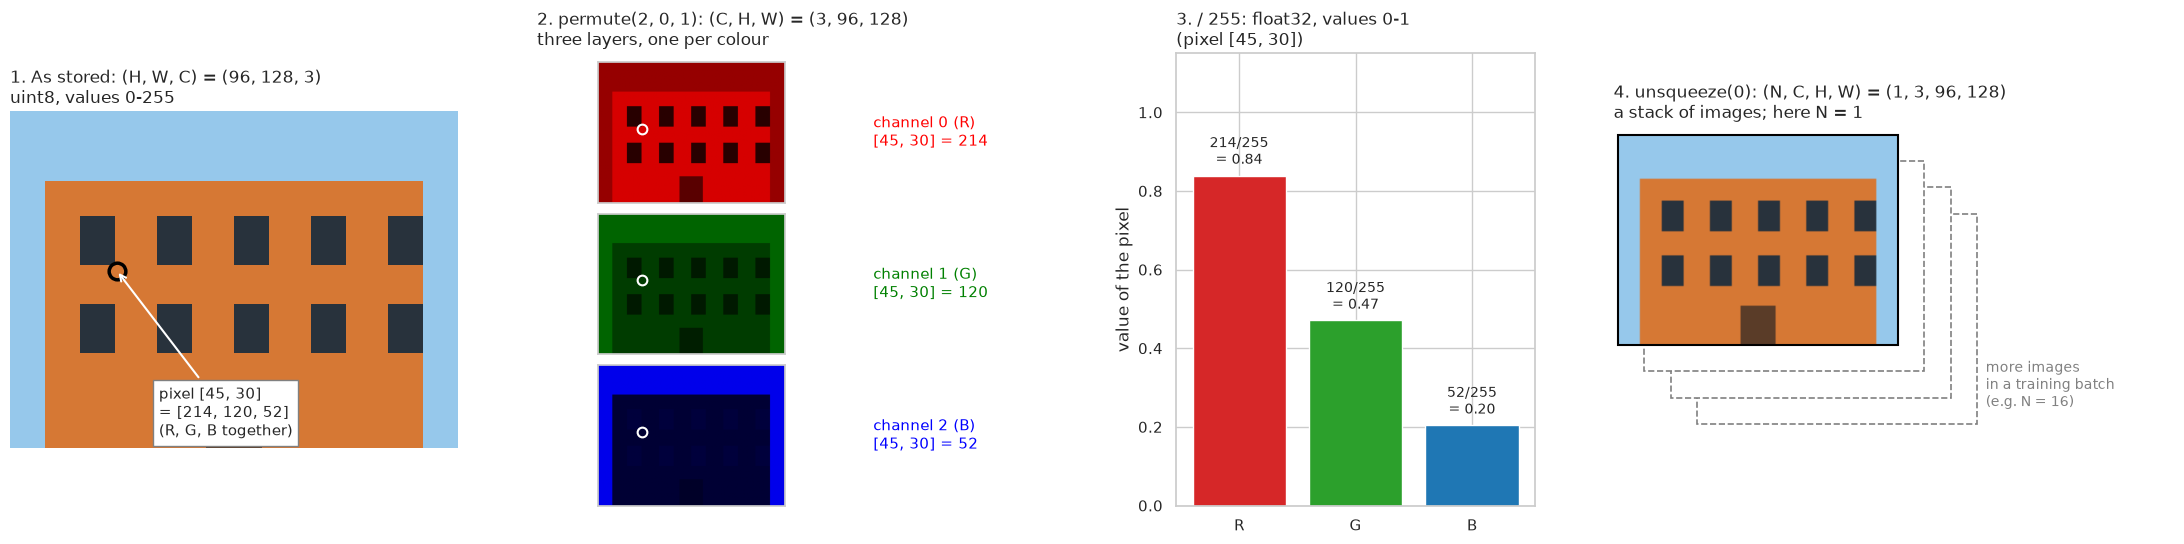

In [8]:
# The same steps on a small drawn picture (in RGB order here, to keep the plot simple)
picture = np.zeros((96, 128, 3), dtype=np.uint8)
picture[:] = (150, 200, 235)                                 # sky
picture[20:, 10:118] = (214, 120, 52)                        # orange wall
for row in (30, 55):
    for col in range(20, 110, 22):
        picture[row:row + 14, col:col + 10] = (40, 50, 60)   # dark windows
picture[78:, 56:72] = (90, 60, 40)                           # door

pic_hwc = torch.from_numpy(picture)          # (H, W, C)
pic_chw = pic_hwc.permute(2, 0, 1)           # (C, H, W)
pic_float = pic_chw.float() / 255            # values 0..1
pic_batch = pic_float.unsqueeze(0)           # (N, C, H, W) with N = 1
r, c = 45, 30                                # one pixel on the wall, followed through the steps

fig, axes = plt.subplots(1, 4, figsize=(22, 5.6), gridspec_kw={"width_ratios": [1, 1.25, 0.8, 1.25]})

# 1. As stored: three numbers per pixel, side by side
ax = axes[0]
ax.imshow(pic_hwc.numpy())
ax.plot(c, r, "o", ms=12, mfc="none", mec="black", mew=2.5)
ax.annotate(f"pixel [{r}, {c}]\n= {pic_hwc[r, c].tolist()}\n(R, G, B together)", (c, r), xytext=(42, 92),
            fontsize=11, arrowprops=dict(arrowstyle="->", lw=1.5), bbox=dict(fc="white", ec="grey"))
ax.set_title(f"1. As stored: (H, W, C) = {tuple(pic_hwc.shape)}\nuint8, values 0-255", loc="left")
ax.set_axis_off()

# 2. permute: the same numbers regrouped into three layers, one per channel (black = 0, full colour = 255)
from matplotlib.colors import LinearSegmentedColormap
axes[1].set_axis_off()
axes[1].set_title(f"2. permute(2, 0, 1): (C, H, W) = {tuple(pic_chw.shape)}\nthree layers, one per colour", loc="left")
for k, (color, name) in enumerate([("red", "R"), ("green", "G"), ("blue", "B")]):
    layer_ax = axes[1].inset_axes([0.0, 0.67 - 0.335 * k, 0.55, 0.31])     # three small images, one under another
    layer_ax.imshow(pic_chw[k].numpy(), cmap=LinearSegmentedColormap.from_list(name, ["black", color]), vmin=0, vmax=255)
    layer_ax.plot(c, r, "o", ms=7, mfc="none", mec="white", mew=1.5)
    layer_ax.set_xticks([])
    layer_ax.set_yticks([])
    axes[1].text(0.6, 0.67 - 0.335 * k + 0.155, f"channel {k} ({name})\n[{r}, {c}] = {pic_chw[k, r, c].item()}",
                 transform=axes[1].transAxes, va="center", fontsize=11, color=color)

# 3. Divide by 255: same picture, numbers between 0 and 1
ax = axes[2]
before, after = pic_chw[:, r, c], pic_float[:, r, c]
bars = ax.bar(["R", "G", "B"], after.numpy(), color=["tab:red", "tab:green", "tab:blue"])
for bar, b, a in zip(bars, before, after):
    ax.text(bar.get_x() + bar.get_width() / 2, a + 0.03, f"{b.item()}/255\n= {a:.2f}", ha="center", fontsize=10)
ax.set_ylim(0, 1.15)
ax.set_ylabel("value of the pixel")
ax.set_title(f"3. / 255: float32, values 0-1\n(pixel [{r}, {c}])", loc="left")

# 4. unsqueeze(0): put the image in a stack (a batch)
ax = axes[3]
for k in range(3, 0, -1):                     # empty slots behind: the other images of a training batch
    offset = 12 * k
    ax.add_patch(plt.Rectangle((offset, offset), 128, 96, fc="white", lw=1.2, ec="grey", ls="--", zorder=5 - k))
ax.imshow(pic_hwc.numpy(), extent=(0, 128, 96, 0), zorder=10)    # our image, in front
ax.add_patch(plt.Rectangle((0, 0), 128, 96, fill=False, lw=1.5, ec="black", zorder=11))
ax.text(128 + 40, 96 + 30, "more images\nin a training batch\n(e.g. N = 16)", fontsize=10, color="grey", va="bottom")
ax.set_xlim(-2, 128 + 36 + 90)
ax.set_ylim(96 + 40, -4)
ax.set_title(f"4. unsqueeze(0): (N, C, H, W) = {tuple(pic_batch.shape)}\na stack of images; here N = 1", loc="left")
ax.set_axis_off()

plt.tight_layout()
save_fig("nb1_01b_image_tensor_steps")
plt.show()

💡 **Tip:** `permute` reorders dimensions, `unsqueeze(0)` adds one in front, `squeeze()` removes dimensions of size 1. You will meet all three when you feed OpenCV images (notebook 2) to neural networks (notebook 3); libraries like Ultralytics do it for you behind the scenes.

## 1.3 Operations and broadcasting

Arithmetic works **element by element**, and `@` is matrix multiplication, the core operation of every neural network. **Broadcasting** lets tensors of different shapes work together: a row of 3 numbers is automatically "stretched" over every row of a table.

Here is Day 2's `StandardScaler`, written by hand in one line thanks to broadcasting:

In [9]:
mean = flats.mean(dim=0)            # one mean per column: shape (3,)
std = flats.std(dim=0)              # one standard deviation per column: shape (3,)
flats_scaled = (flats - mean) / std # (4, 3) - (3,) -> broadcast over the 4 rows

print("Column means:", mean)
print("Scaled table:\n", flats_scaled.round(decimals=2))
print("Means after scaling:", flats_scaled.mean(dim=0).round(decimals=3))

# Matrix multiplication: 4 flats x 3 features @ 3 weights -> 4 scores, one per flat
weights = torch.tensor([0.5, 0.3, 0.2])
print("\nWeighted score per flat:", flats_scaled @ weights)

Column means: tensor([106.2500,   2.7500,   2.0000])
Scaled table:
 tensor([[ 0.3700,  0.2600,  0.0000],
        [-1.1200, -0.7800, -1.2200],
        [-0.4400, -0.7800,  0.0000],
        [ 1.1900,  1.3100,  1.2200]])
Means after scaling: tensor([-0., 0., 0.])

Weighted score per flat: tensor([ 0.2650, -1.0400, -0.4556,  1.2306])


## 1.4 NumPy ⇄ PyTorch

Everything from Days 1–3 (pandas, NumPy, scikit-learn) converts easily:

In [10]:
array = np.array([[1.0, 2.0], [3.0, 4.0]])
tensor = torch.from_numpy(array)        # NumPy -> PyTorch (shares the same memory!)
back = tensor.numpy()                   # PyTorch -> NumPy

array[0, 0] = 100                       # changing the array also changes the tensor
print(tensor)

# From a pandas DataFrame: go through .to_numpy(), and convert to float32 for networks
df = pd.DataFrame({"area": [120, 65], "bedrooms": [3, 2]})
print(torch.tensor(df.to_numpy(), dtype=torch.float32))

tensor([[100.,   2.],
        [  3.,   4.]], dtype=torch.float64)
tensor([[120.,   3.],
        [ 65.,   2.]])


⚠️ **Watch out:** `torch.from_numpy` **shares memory** with the array (no copy, which is fast), so changing one changes the other. Use `torch.tensor(array)` if you want an independent copy.

## 1.5 Moving to the GPU

`.to(DEVICE)` moves a tensor to the GPU (if you have one). Let's measure why it matters: one multiplication of two 4,000 × 4,000 matrices (64 billion multiply-adds).

In [11]:
size = 4000
a = torch.rand(size, size)
b = torch.rand(size, size)

start = time.time()
_ = a @ b
cpu_seconds = time.time() - start
print(f"CPU: {cpu_seconds:.3f} s")

if DEVICE != "cpu":
    a_gpu, b_gpu = a.to(DEVICE), b.to(DEVICE)
    _ = a_gpu @ b_gpu                          # a first "warm-up" call (the GPU initialises itself)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    start = time.time()
    for _ in range(10):
        _ = a_gpu @ b_gpu
    if DEVICE == "cuda":
        torch.cuda.synchronize()               # wait until the GPU has really finished
    gpu_seconds = (time.time() - start) / 10
    print(f"{DEVICE.upper()}: {gpu_seconds:.4f} s  ->  about {cpu_seconds / gpu_seconds:.0f}x faster")
else:
    print("No GPU found: everything in this notebook still runs on the CPU, just a bit slower.")

CPU: 0.662 s
CUDA: 0.0213 s  ->  about 31x faster


💡 **Tip:** the model **and** the data must be on the same device. The usual pattern is `model.to(DEVICE)` once, and `x.to(DEVICE)` for every batch of data.

## 1.6 Autograd: tensors that compute their own gradients

Learning needs to know **how the error changes when a weight changes**: the **gradient** (the slope). PyTorch computes it automatically. Mark a tensor with `requires_grad=True`, compute something with it, call `.backward()`, and the slope appears in `.grad`.

Let's check it on a function we can differentiate by hand: $y = x^2 + 2x$, whose slope is $2x + 2$.

y at x = 3:              15.0
slope by autograd:       8.0
slope by hand (2x + 2):  8.0
Figure saved to figures/nb1_01_gradient.png


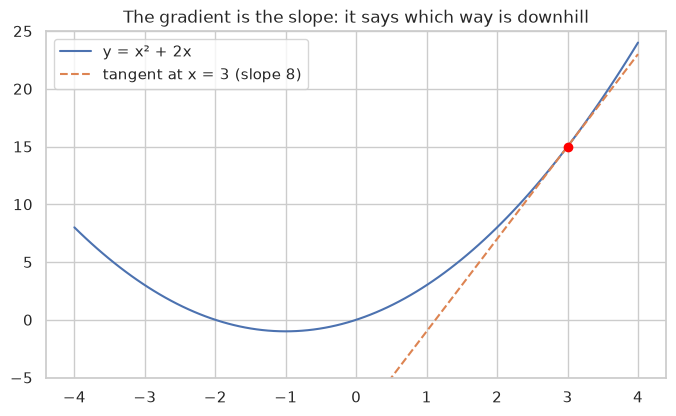

In [12]:
x = torch.tensor(3.0, requires_grad=True)
y = x**2 + 2 * x
y.backward()                     # compute dy/dx

print(f"y at x = 3:              {y.item():.1f}")
print(f"slope by autograd:       {x.grad.item():.1f}")
print(f"slope by hand (2x + 2):  {2 * 3 + 2:.1f}")

# Draw the function and the tangent line given by the gradient
xs = torch.linspace(-4, 4, 100)
plt.figure(figsize=(8, 4.5))
plt.plot(xs, xs**2 + 2 * xs, label="y = x² + 2x")
tangent = y.item() + x.grad.item() * (xs - 3)
plt.plot(xs, tangent, "--", label=f"tangent at x = 3 (slope {x.grad.item():.0f})")
plt.scatter([3], [y.item()], color="red", zorder=3)
plt.ylim(-5, 25)
plt.title("The gradient is the slope: it says which way is downhill")
plt.legend()
save_fig("nb1_01_gradient")
plt.show()

The gradient tells us **which direction increases the function, and how fast**. To make an error *smaller*, we step in the **opposite** direction of the gradient. That single idea, repeated millions of times, is how every neural network learns (section 3).

# 2. The neuron and the network

## 2.1 One neuron = a weighted sum + an activation

A **neuron** takes some inputs, multiplies each by a **weight**, adds them up with a **bias**, and passes the result through an **activation function**:

```
 inputs        weights
 area ───────── w₁ ─┐
 height ─────── w₂ ─┼──►  z = w₁·area + w₂·height + w₃·glazing + b  ──►  activation(z)  ──► output
 glazing ────── w₃ ─┘
```

You already know this! With **no activation** it is Day 2's **linear regression**; with a **sigmoid** activation (which squeezes any number into 0…1) it is **logistic regression**. In PyTorch, the weighted sum is a `nn.Linear` layer:

In [13]:
neuron = nn.Sequential(
    nn.Linear(in_features=3, out_features=1),   # z = w·x + b  (3 weights + 1 bias)
    nn.Sigmoid(),                               # squeeze into 0..1: a "probability"
)
building = torch.tensor([[0.8, 7.0, 0.25]])     # one building (scaled values), as a batch of 1

print("Output (random weights, not trained yet):", neuron(building).item())
print("Weights:", neuron[0].weight.data, "bias:", neuron[0].bias.data)

Output (random weights, not trained yet): 0.9671999216079712
Weights: tensor([[ 0.1566,  0.5379, -0.1113]]) bias: tensor([-0.4790])


### Looking inside a network

A network is only numbers arranged in layers, so we can open it and look. We use five tools for the rest of the notebook:

| Tool | What it shows | From |
|---|---|---|
| `summary(model, input_data=...)` | Every layer, the shape of what goes in and comes out, and its number of parameters | the `torchinfo` library |
| `parameter_table(model)` | Every weight matrix and bias vector: shape, how many numbers, typical values | written below |
| `draw_network(model)` | The neurons as circles and the weights as lines | written below |
| `layer_outputs(model, x)` | What comes out of each layer when an example passes through | written below |
| `make_dot(output)` | The chain of calculations PyTorch recorded, which training follows backwards | the `torchviz` library |

In Keras and in many diagrams, a `nn.Linear` layer is called a **dense** or **fully connected** layer: every input is connected to every neuron. The drawing below makes that literal.

In [14]:
def parameter_table(model):
    # One row per weight matrix and bias vector: its shape, how many numbers it holds and their spread
    rows = []
    for name, p in model.named_parameters():
        values = p.detach().cpu().numpy()
        rows.append({"parameter": name, "shape": tuple(values.shape), "count": values.size,
                     "mean": values.mean(), "std": values.std(), "min": values.min(), "max": values.max()})
    return pd.DataFrame(rows).set_index("parameter")


def layer_outputs(model, x):
    # Pass x through a Sequential model one layer at a time and keep what comes out of each layer
    outputs = []
    with torch.no_grad():
        for name, layer in model.named_children():
            x = layer(x)
            outputs.append((f"{name}: {layer.__class__.__name__}", x.cpu()))
    return outputs


def draw_network(model, input_names=None, output_names=None, max_neurons=12, weight_scale=None, title=None, ax=None):
    # Draw the Linear (dense) layers of a model: circles are neurons, lines are weights.
    # Blue = positive weight, red = negative; the thicker and darker the line, the larger the weight.
    # weight_scale = the weight drawn at full strength (default: the largest one in each layer).
    # Wide layers only show their first `max_neurons` neurons.
    layers = list(model) if isinstance(model, nn.Sequential) else [model]
    linears = [layer for layer in layers if isinstance(layer, nn.Linear)]

    # A label under each layer, e.g. "Linear 8→32 + ReLU"
    labels = []
    for layer in layers:
        if isinstance(layer, nn.Linear):
            labels.append(f"Linear {layer.in_features}→{layer.out_features}")
        elif not isinstance(layer, nn.Dropout) and labels:
            labels[-1] += f"\n+ {layer.__class__.__name__}"

    sizes = [linears[0].in_features] + [layer.out_features for layer in linears]
    shown = [min(n, max_neurons) for n in sizes]
    spacing = [min(2 / max(n - 1, 1), 0.6) for n in shown]           # small layers are spread out more
    ys = [(np.arange(n) - (n - 1) / 2) * -gap for n, gap in zip(shown, spacing)]   # vertical position of each neuron

    if ax is None:
        fig, ax = plt.subplots(figsize=(2.8 * len(sizes) + 1, 6))

    # Lines: one per weight
    for l, layer in enumerate(linears):
        W = layer.weight.detach().cpu().numpy()[:shown[l + 1], :shown[l]]   # (outputs, inputs)
        scale = weight_scale or np.abs(W).max()
        for j, y_out in enumerate(ys[l + 1]):
            for i, y_in in enumerate(ys[l]):
                strength = min(abs(W[j, i]) / scale, 1)
                ax.plot([l, l + 1], [y_in, y_out], color="tab:blue" if W[j, i] > 0 else "tab:red",
                        lw=0.3 + 3 * strength, alpha=0.15 + 0.75 * strength, zorder=1)
                if W.size <= 12:                                           # tiny network: write the value too
                    ax.text(l + 0.3, y_in + 0.3 * (y_out - y_in), f"{W[j, i]:+.2f}", fontsize=9,
                            ha="center", va="bottom", color="dimgrey")

    # Circles: one per neuron, and the labels
    circle_size = np.clip(2500 / max(shown), 60, 700)
    for l, (n, y) in enumerate(zip(sizes, ys)):
        ax.scatter(np.full(len(y), l), y, s=circle_size, color="lightgrey" if l == 0 else "white",
                   edgecolors="black", zorder=2)
        if n > len(y):
            ax.text(l, y.min() - 0.12, f"+ {n - len(y)} more", ha="center", va="top", fontsize=9)
        ax.text(l, -1.3, "Input" if l == 0 else labels[l - 1], ha="center", va="top", fontsize=10)
    for name, y in zip(input_names or [], ys[0]):
        ax.text(-0.15, y, name, ha="right", va="center", fontsize=9)
    for name, y in zip(output_names or [], ys[-1]):
        ax.text(len(sizes) - 0.85, y, name, ha="left", va="center", fontsize=9)

    n_params = sum(p.numel() for p in model.parameters())
    ax.set_title(title or f"{n_params:,} parameters")
    ax.set_xlim(-1, len(sizes) - 0.2)
    ax.set_ylim(-1.7, 1.2)
    ax.axis("off")
    return ax

In [15]:
print(summary(neuron, input_data=building, col_names=["input_size", "output_size", "num_params"], verbose=0))
parameter_table(neuron)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [1, 3]                    [1, 1]                    --
├─Linear: 1-1                            [1, 3]                    [1, 1]                    4
├─Sigmoid: 1-2                           [1, 1]                    [1, 1]                    --
Total params: 4
Trainable params: 4
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.00
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 0.00
Estimated Total Size (MB): 0.00


,shape,count,mean,std,min,max
parameter,,,,,,
0.weight,"(1, 3)",3,0.194,0.266,-0.111,0.538
0.bias,"(1,)",1,-0.479,0.000,-0.479,-0.479


`summary` reads like a bill of quantities: the `Linear` layer receives **1 building × 3 features** and returns **1 number**, using **4 parameters** (3 weights + 1 bias). The sigmoid has no parameters: it only reshapes the number. Now the same neuron as a drawing, with its (still random) weights on the lines:

Figure saved to figures/nb1_02a_neuron_drawing.png


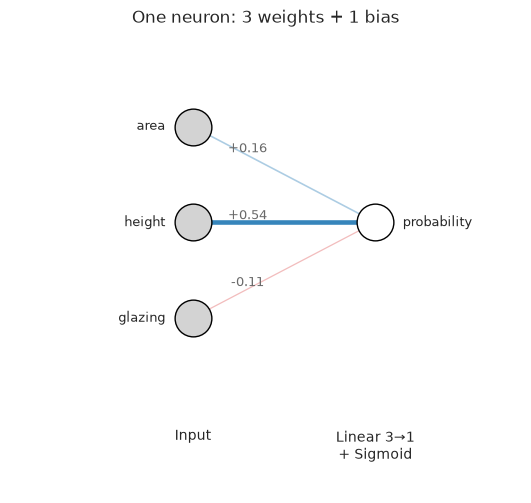

By hand:  z = (0.157 × 0.80) + (0.538 × 7.00) + (-0.111 × 0.25) + -0.479 = 3.384
0: Linear    -> [[3.384]]
1: Sigmoid   -> [[0.967]]


In [16]:
draw_network(neuron, input_names=["area", "height", "glazing"], output_names=["probability"],
             title="One neuron: 3 weights + 1 bias")
save_fig("nb1_02a_neuron_drawing")
plt.show()

# The forward pass, step by step: the weighted sum by hand, then the same thing layer by layer
w, b = neuron[0].weight.data[0], neuron[0].bias.data[0]
z = (w * building[0]).sum() + b
print("By hand:  z = " + " + ".join(f"({wi:.3f} × {xi:.2f})" for wi, xi in zip(w, building[0])) + f" + {b:.3f} = {z:.3f}")
for name, output in layer_outputs(neuron, building):
    print(f"{name:<12} -> {output.numpy().round(3)}")

The first layer gives exactly the weighted sum we computed by hand; the sigmoid then squeezes it into 0…1.

Training will need to know **how each weight affected the output**. For that, PyTorch records every calculation of the forward pass as a graph (the autograd of section 1.6). `torchviz` draws that graph:

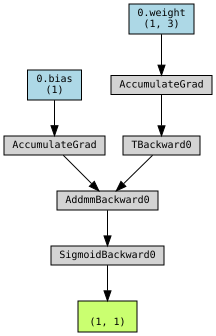

Figure saved to figures/nb1_02b_neuron_autograd_graph.png


In [17]:
from IPython.display import SVG, display
import graphviz
from torchviz import make_dot


def print_autograd_graph(step, names, depth=0):
    # Text version of the graph: each calculation, and indented below it the steps it came from
    if hasattr(step, "variable"):                    # an end point: one of the model's parameters
        print("    " * depth + f"{names[id(step.variable)]} {tuple(step.variable.shape)}")
        return
    print("    " * depth + type(step).__name__)
    for previous, _ in step.next_functions:
        if previous is not None:
            print_autograd_graph(previous, names, depth + 1)


output = neuron(building)       # a normal forward pass (no torch.no_grad), so PyTorch records the graph
graph = make_dot(output, params=dict(neuron.named_parameters()))
try:
    display(SVG(graph.pipe(format="svg")))
    graph.render(FIG_DIR / "nb1_02b_neuron_autograd_graph", format="png", cleanup=True)
    print(f"Figure saved to {FIG_DIR / 'nb1_02b_neuron_autograd_graph.png'}")
except graphviz.ExecutableNotFound:
    print("The Graphviz program is not installed (see the Setup section), so here is the graph as text:\n")
    print_autograd_graph(output.grad_fn, {id(p): name for name, p in neuron.named_parameters()})

How to read the graph, from the bottom (the output) up:
- **`SigmoidBackward0`**: the activation, the last calculation.
- **`AddmmBackward0`**: "**add** + **m**atrix **m**ultiply", i.e. $w \cdot x + b$: the `Linear` layer.
- **`TBackward0`**: a transpose, PyTorch's way of lining up the weight matrix for the multiplication.
- **Blue boxes** (`0.weight (1, 3)` and `0.bias (1)`): the parameters, the only things training will change.

When we call `loss.backward()` (section 3), PyTorch walks this graph **from the output back to the blue boxes** and computes a gradient for each weight on the way. That is **backpropagation**. Bigger networks just have longer graphs.

### Activation functions

The activation is what makes networks more powerful than linear models. Without it, stacking layers would still give a straight line (a sum of weighted sums is just another weighted sum).

Figure saved to figures/nb1_02_activations.png


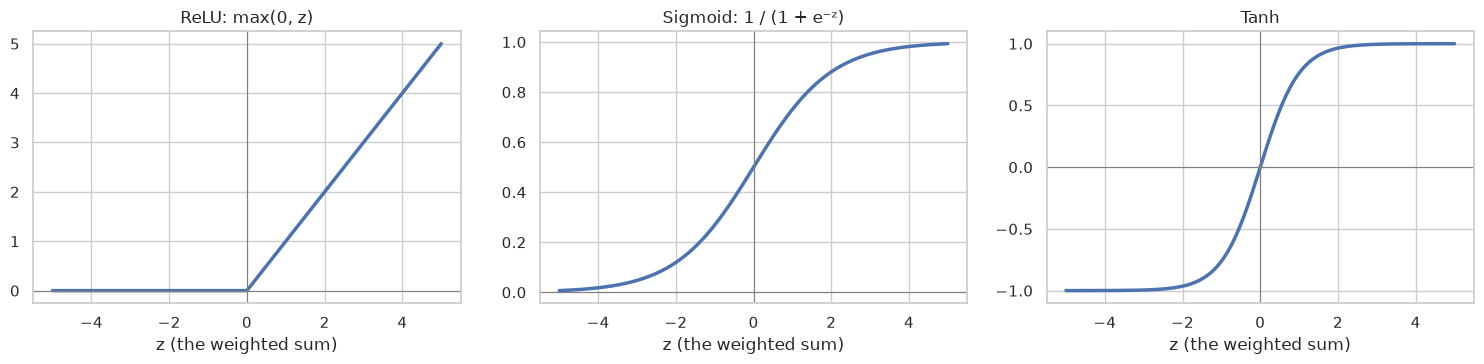

In [18]:
z = torch.linspace(-5, 5, 200)
activations = {
    "ReLU: max(0, z)": torch.relu(z),
    "Sigmoid: 1 / (1 + e⁻ᶻ)": torch.sigmoid(z),
    "Tanh": torch.tanh(z),
}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharex=True)
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(z, values, lw=2.5)
    ax.axhline(0, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("z (the weighted sum)")
plt.tight_layout()
save_fig("nb1_02_activations")
plt.show()

| Activation | Output | Used for |
|---|---|---|
| **ReLU** | 0 for negative inputs, the input itself otherwise | The **default** inside networks: simple and fast to train |
| **Sigmoid** | 0 … 1 | The **last** neuron of a yes/no classifier (a probability) |
| **Tanh** | −1 … 1 | Some older or recurrent networks |
| **Softmax** (not plotted) | Probabilities over several classes, summing to 1 | The **last** layer of a multi-class classifier (energy class A/B/C, helmet / vest / person…) |

## 2.2 Layers: many neurons, many levels

A **layer** is many neurons side by side, each with its own weights, all looking at the same inputs. A **multi-layer perceptron (MLP)** stacks layers: the outputs of one layer are the inputs of the next.

```
  INPUT            HIDDEN LAYER 1      HIDDEN LAYER 2        OUTPUT
 (8 features)      (32 neurons)        (32 neurons)          (3 classes)

  compactness ─┐   ○ ○ ○ ○ ○ ○ ○      ○ ○ ○ ○ ○ ○ ○          ○  A
  surface     ─┤   ○ ○ ○ ○ ○ ○ ○  ─►  ○ ○ ○ ○ ○ ○ ○    ─►    ○  B
  ...         ─┤   ○ ○ ○ ○ ○ ○ ○      ○ ○ ○ ○ ○ ○ ○          ○  C
  glazing     ─┘     ReLU                ReLU               softmax
```

Each layer can combine the previous layer's outputs into more complex "features". This is the **deep** in deep learning.

Let's see the effect of hidden layers on the "two moons" toy data from Day 3: a single neuron (logistic regression) can only draw a **straight** border; a small MLP can bend it.

Figure saved to figures/nb1_03_moons_boundaries.png


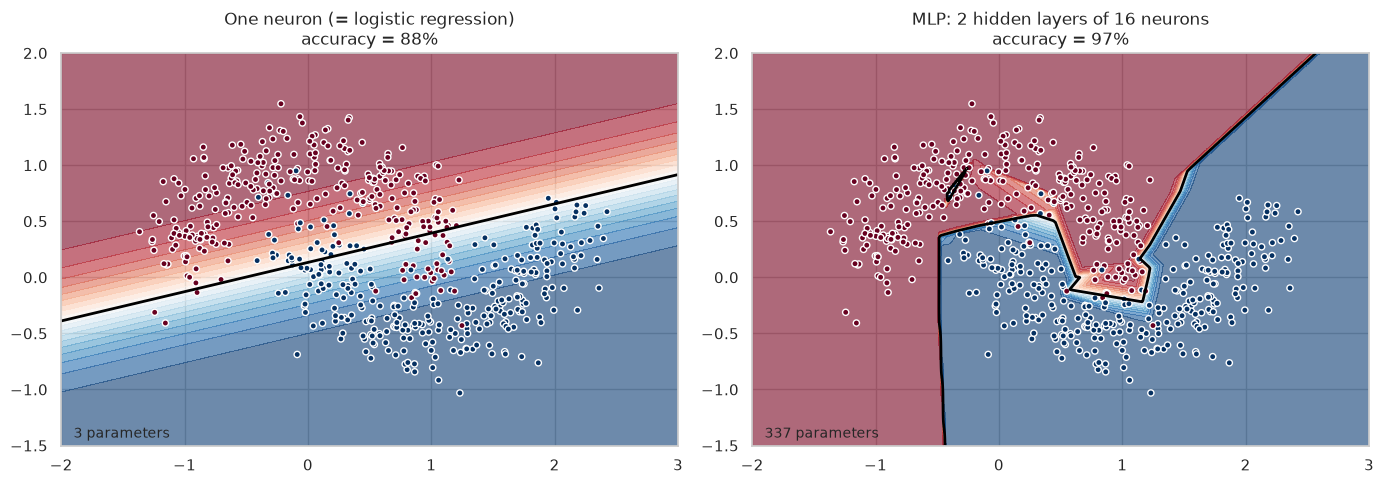

In [19]:
from sklearn.datasets import make_moons

X_moons, y_moons = make_moons(n_samples=600, noise=0.2, random_state=RANDOM_STATE)
X_t = torch.tensor(X_moons, dtype=torch.float32)
y_t = torch.tensor(y_moons, dtype=torch.float32).unsqueeze(1)


def train_quickly(model, X, y, epochs=2000, lr=0.05):
    # A minimal training loop (explained in section 3): repeat "predict, measure error, adjust"
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    loss_fn = nn.BCEWithLogitsLoss()          # error measure for yes/no problems
    for _ in range(epochs):
        optimizer.zero_grad()
        loss = loss_fn(model(X), y)
        loss.backward()
        optimizer.step()
    return model


torch.manual_seed(RANDOM_STATE)
models = {
    "One neuron (= logistic regression)": nn.Linear(2, 1),
    "MLP: 2 hidden layers of 16 neurons": nn.Sequential(nn.Linear(2, 16), nn.ReLU(),
                                                        nn.Linear(16, 16), nn.ReLU(),
                                                        nn.Linear(16, 1)),
}

# A grid of points covering the plot, to draw each model's decision border
gx, gy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))
grid = torch.tensor(np.column_stack([gx.ravel(), gy.ravel()]), dtype=torch.float32)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, model) in zip(axes, models.items()):
    train_quickly(model, X_t, y_t)
    with torch.no_grad():
        probability = torch.sigmoid(model(grid)).reshape(gx.shape).numpy()
        accuracy = ((model(X_t) > 0).float() == y_t).float().mean().item()
    ax.contourf(gx, gy, probability, levels=20, cmap="RdBu", alpha=0.6)
    ax.contour(gx, gy, probability, levels=[0.5], colors="black", linewidths=2)
    ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap="RdBu", edgecolor="white", s=20)
    ax.set_title(f"{name}\naccuracy = {accuracy:.0%}")
    n_params = sum(p.numel() for p in model.parameters())
    ax.text(0.02, 0.02, f"{n_params} parameters", transform=ax.transAxes, fontsize=10)
plt.tight_layout()
save_fig("nb1_03_moons_boundaries")
plt.show()

The single neuron draws a straight line and misclassifies the tips of both moons. Two small hidden layers bend the border around the shapes. The price: many more **parameters** (weights and biases) to learn, and therefore more data needed and more risk of overfitting (section 5).

🤔 **Think about it:** the MLP here has a few hundred parameters. The YOLO model in notebook 3 has millions, and large language models have billions. What does that imply for the amount of data and computing power they need?

### Looking inside the moons network

Where do those parameters live, and what does each neuron do? First the bill of quantities and the drawing of the trained MLP:

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [600, 2]                  [600, 1]                  --
├─Linear: 1-1                            [600, 2]                  [600, 16]                 48
├─ReLU: 1-2                              [600, 16]                 [600, 16]                 --
├─Linear: 1-3                            [600, 16]                 [600, 16]                 272
├─ReLU: 1-4                              [600, 16]                 [600, 16]                 --
├─Linear: 1-5                            [600, 16]                 [600, 1]                  17
Total params: 337
Trainable params: 337
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.20
Input size (MB): 0.00
Forward/backward pass size (MB): 0.16
Params size (MB): 0.00
Estimated Total Size (MB): 0.16
Figure saved to figures/nb1_03b_moons_network.png


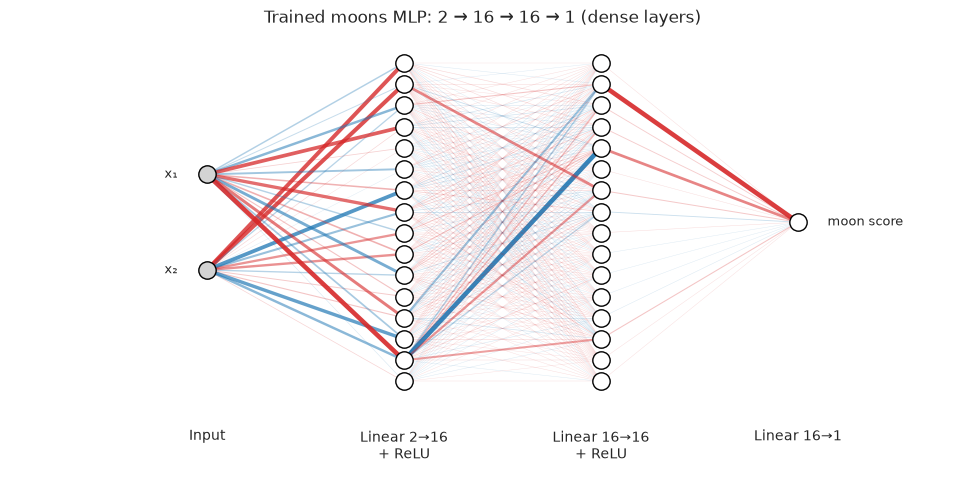

In [20]:
moons_mlp = models["MLP: 2 hidden layers of 16 neurons"]
print(summary(moons_mlp, input_data=X_t, col_names=["input_size", "output_size", "num_params"], verbose=0))

draw_network(moons_mlp, input_names=["x₁", "x₂"], output_names=["moon score"], max_neurons=16,
             title="Trained moons MLP: 2 → 16 → 16 → 1 (dense layers)")
save_fig("nb1_03b_moons_network")
plt.show()

- `summary` follows the data: **600 points × 2 coordinates** go in, every hidden layer turns them into **600 × 16** numbers, and the output is **600 × 1** score. The parameters per layer are inputs × outputs + one bias per output: 2×16+16 = **48**, 16×16+16 = **272**, 16×1+1 = **17**, together **337**.
- In the drawing, every neuron is connected to **every** neuron of the next layer: that is why these layers are called **dense**. The middle layer alone has 256 lines.

The drawing shows the weights, but not what they **do**. We can find out by sending every point of the plane through the network with `layer_outputs` and colouring the plane by the output of one neuron at a time (yellow = high, dark = 0):

Figure saved to figures/nb1_03c_moons_hidden_neurons.png


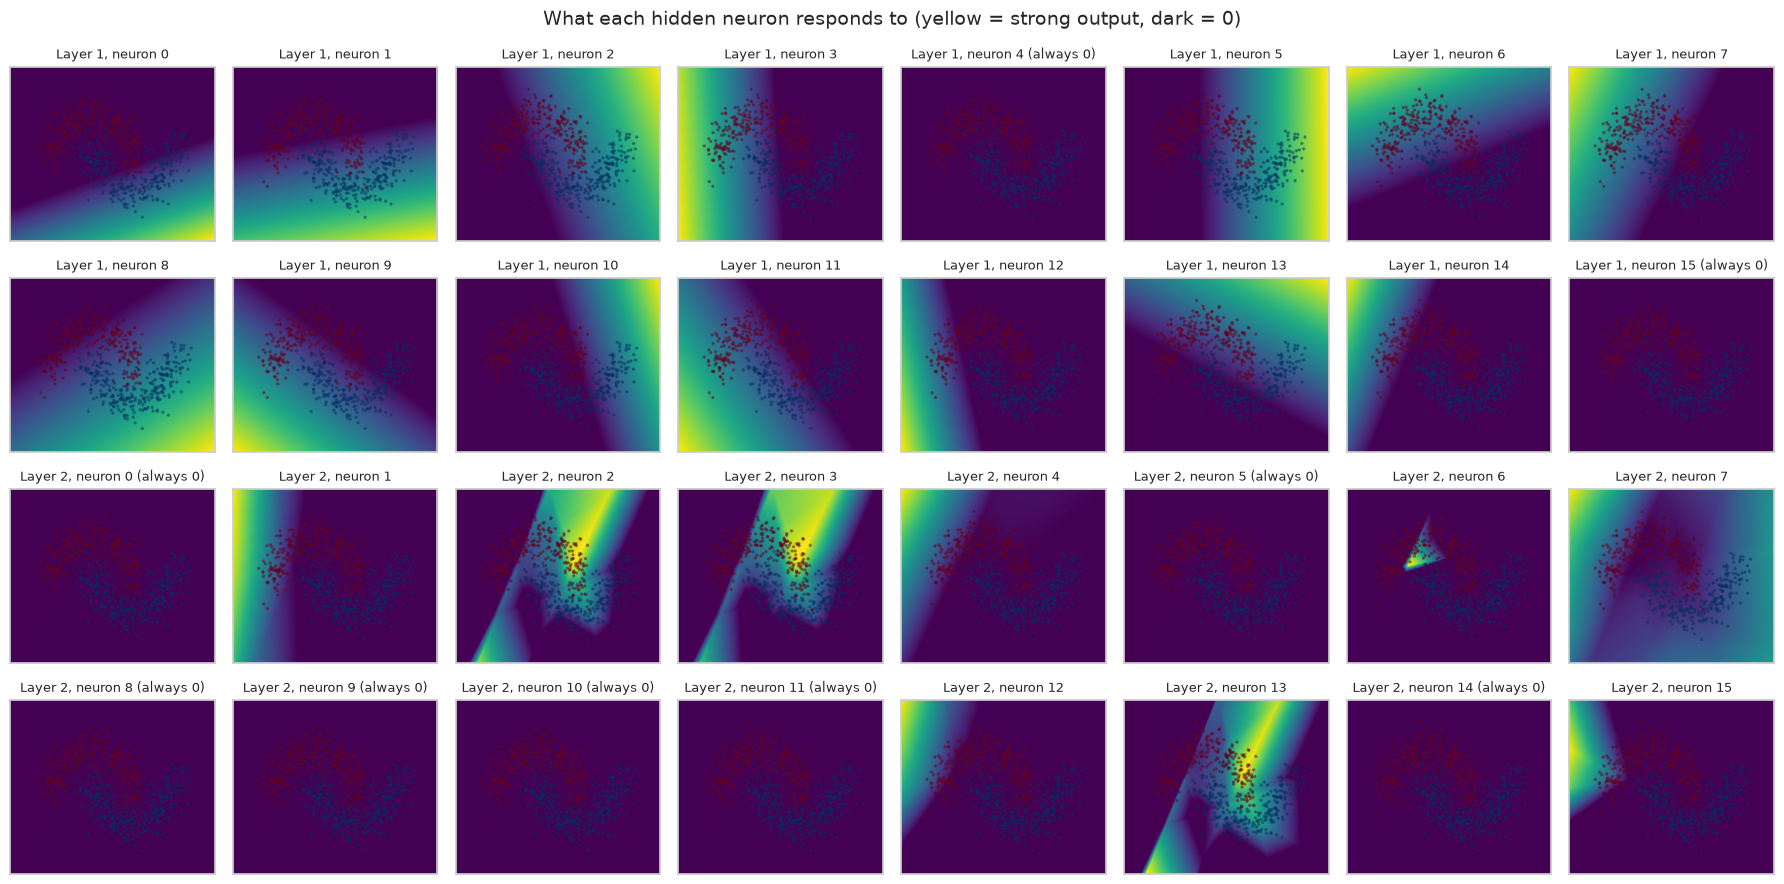

In [21]:
outputs = layer_outputs(moons_mlp, grid)     # [Linear, ReLU, Linear, ReLU, Linear]
hidden = {"Layer 1": outputs[1][1], "Layer 2": outputs[3][1]}   # the outputs after each ReLU

fig, axes = plt.subplots(4, 8, figsize=(18, 9))
for block, (layer_name, values) in enumerate(hidden.items()):
    for neuron_id in range(16):
        ax = axes[2 * block + neuron_id // 8, neuron_id % 8]
        neuron_map = values[:, neuron_id].reshape(gx.shape).numpy()
        ax.imshow(neuron_map, extent=(-2, 3, -1.5, 2), origin="lower", cmap="viridis", aspect="auto")
        ax.scatter(X_moons[:, 0], X_moons[:, 1], c=y_moons, cmap="RdBu", s=2, alpha=0.4)
        dead = " (always 0)" if neuron_map.max() == 0 else ""
        ax.set_title(f"{layer_name}, neuron {neuron_id}{dead}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
plt.suptitle("What each hidden neuron responds to (yellow = strong output, dark = 0)", fontsize=14)
plt.tight_layout()
save_fig("nb1_03c_moons_hidden_neurons")
plt.show()

This is how depth works:
- Every **layer-1** neuron is one weighted sum of $x_1$ and $x_2$ followed by ReLU, so it can only do one thing: switch on **on one side of a straight line**, and get stronger the further you go. Each map is a tilted ramp with a straight edge, like the single neuron of section 2.1.
- Each **layer-2** neuron adds up several of those ramps, so its maps have **bent and cornered** shapes: neurons 2, 3 and 13 light up along the inside of the curve where the two moons meet. Combining straight pieces is how the network gets a curved border.
- Some neurons are **"always 0"** in this window: 2 of the 16 in layer 1 and 7 of the 16 in layer 2. Their weighted sum is negative everywhere, so ReLU switches them off. These are called **dead neurons**: they take part in nothing and stop learning, because their gradient is 0 too. It does no harm here (the network still reaches 97%), but it shows that a network often uses **less** capacity than it has.

🤔 **Think about it:** the output neuron does the same thing one level up: it adds up the layer-2 maps with its own weights (the last column of the drawing) and puts its border where the sum crosses 0.

# 3. How a network learns

Training repeats four steps, thousands of times:

```
   ┌──────────────────────────────────────────────────────────────────────────┐
   │ 1. FORWARD   feed a batch of examples through the network → predictions  │
   │ 2. LOSS      compare predictions with the true answers → one error number│
   │ 3. BACKWARD  autograd computes the gradient of the loss for EVERY weight │
   │              ("backpropagation")                                         │
   │ 4. STEP      move every weight a little bit downhill:                    │
   │              weight ← weight − learning_rate × gradient                  │
   └──────────────────────────────────────────────────────────────────────────┘
```

| Term | Meaning |
|---|---|
| **Loss** | The error measure the network minimises. **MSE** (mean squared error) for regression, **cross-entropy** for classification |
| **Gradient descent** | Walking downhill on the loss, one small step at a time |
| **Learning rate** | The size of each step |
| **Batch** | The group of examples used for one step (e.g. 32 rows or 16 images) |
| **Epoch** | One full pass over the whole training set |
| **Optimizer** | The rule that makes the steps: `SGD` (plain gradient descent) or `Adam` (adapts the step for each weight; a good default) |

## 3.1 Gradient descent by hand

The smallest possible "network": one weight and one bias, fitting a straight line through made-up data (construction cost vs floor area). We write the four steps ourselves, using autograd for the gradients.

In [22]:
gen = torch.Generator().manual_seed(RANDOM_STATE)
area = torch.rand(80, generator=gen) * 4 + 0.5                 # floor area, in hundreds of m²
cost = 1.8 * area + 0.7 + torch.randn(80, generator=gen) * 0.4   # cost in M€: the "true" rule + noise

w = torch.tensor(0.0, requires_grad=True)   # start from a bad guess
b = torch.tensor(0.0, requires_grad=True)
learning_rate = 0.01
history, snapshots = [], {}

for step in range(301):
    prediction = w * area + b                       # 1. forward
    loss = ((prediction - cost) ** 2).mean()        # 2. loss (MSE)
    if step in (0, 5, 20, 300):
        snapshots[step] = (w.item(), b.item(), loss.item())   # the line BEFORE this step's update
    loss.backward()                                 # 3. backward: fills w.grad and b.grad
    with torch.no_grad():                           # 4. step (no gradient tracking for the update itself)
        w -= learning_rate * w.grad
        b -= learning_rate * b.grad
    w.grad.zero_()                                  # reset, otherwise gradients add up
    b.grad.zero_()
    history.append(loss.item())

print(f"Learned rule: cost ≈ {w.item():.2f} × area + {b.item():.2f}   (true rule: 1.80 × area + 0.70)")

Learned rule: cost ≈ 1.80 × area + 0.75   (true rule: 1.80 × area + 0.70)


Figure saved to figures/nb1_04_gradient_descent.png


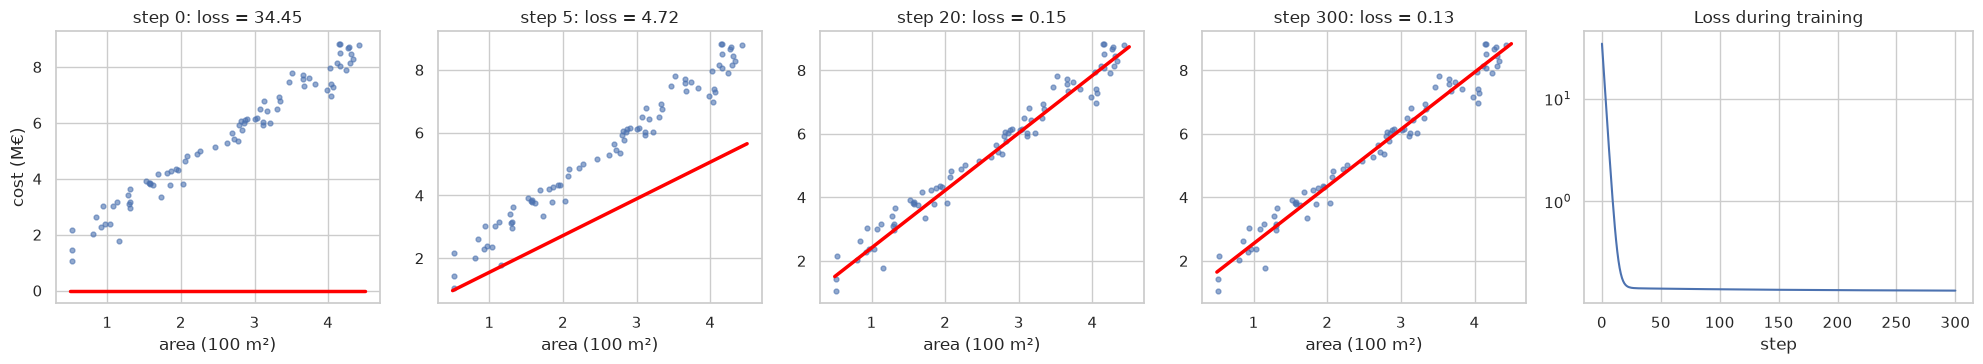

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(20, 3.8), gridspec_kw={"width_ratios": [1, 1, 1, 1, 1.2]})
xs = torch.linspace(0.5, 4.5, 10)
for ax, (step, (w_s, b_s, loss_s)) in zip(axes, snapshots.items()):
    ax.scatter(area, cost, s=12, alpha=0.6)
    ax.plot(xs, w_s * xs + b_s, color="red", lw=2.5)
    ax.set_title(f"step {step}: loss = {loss_s:.2f}")
    ax.set_xlabel("area (100 m²)")
axes[0].set_ylabel("cost (M€)")
axes[4].plot(history)
axes[4].set_yscale("log")
axes[4].set_title("Loss during training")
axes[4].set_xlabel("step")
plt.tight_layout()
save_fig("nb1_04_gradient_descent")
plt.show()

The red line starts flat (both parameters at 0) and moves step by step towards the data. The loss drops quickly at first and then flattens out: the line is as good as it can get. A neural network does **exactly this**, with millions of weights instead of two.

## 3.2 The learning rate: the size of the steps

The learning rate is the most important setting of training. Same problem, three step sizes:

Figure saved to figures/nb1_05_learning_rates.png


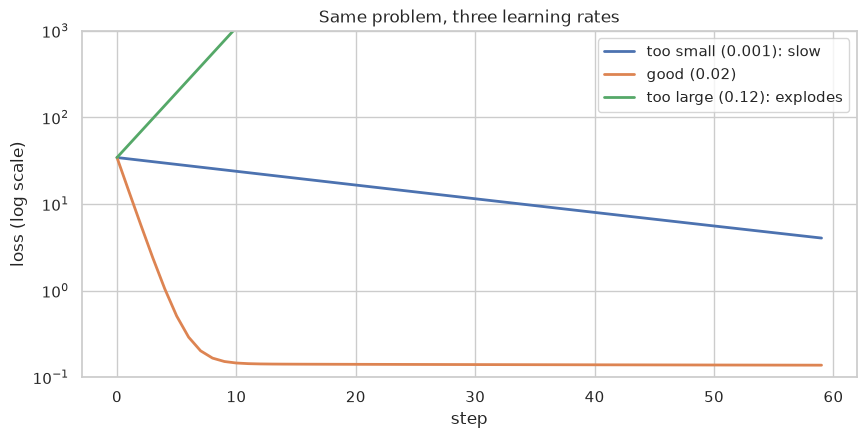

In [24]:
def fit_line(learning_rate, steps=60):
    w = torch.tensor(0.0, requires_grad=True)
    b = torch.tensor(0.0, requires_grad=True)
    losses = []
    for _ in range(steps):
        loss = ((w * area + b - cost) ** 2).mean()
        loss.backward()
        with torch.no_grad():
            w -= learning_rate * w.grad
            b -= learning_rate * b.grad
        w.grad.zero_()
        b.grad.zero_()
        losses.append(loss.item())
    return losses


plt.figure(figsize=(10, 4.5))
for lr, label in [(0.001, "too small (0.001): slow"), (0.02, "good (0.02)"), (0.12, "too large (0.12): explodes")]:
    plt.plot(fit_line(lr), label=label, lw=2)
plt.yscale("log")
plt.ylim(0.1, 1000)                       # the "too large" curve leaves the plot upwards
plt.xlabel("step")
plt.ylabel("loss (log scale)")
plt.title("Same problem, three learning rates")
plt.legend()
save_fig("nb1_05_learning_rates")
plt.show()

- **Too small:** every step is tiny, so training needs far more steps (and time) to get anywhere.
- **Good:** fast and steady.
- **Too large:** every step overshoots the minimum and lands higher up on the other side, so the loss grows instead of shrinking: it **explodes**.

💡 **Tip:** with the `Adam` optimizer, `lr = 0.001` is a classic starting point. If the loss does not decrease, try 10× smaller; if it decreases very slowly, try 3–10× larger.

# 4. Hands-on: a neural network on the energy dataset

Time for a real (small) network. We reuse the **energy efficiency dataset from Day 2** (768 simulated buildings, 8 design parameters) and predict its **energy class**: A (heating load ≤ 15 kWh/m²), B (15–30) or C (> 30). On Day 2, **gradient boosting got 153 of the 154 test buildings right**. Can a neural network do as well?

In [25]:
energy = kh.dataset_load(KaggleDatasetAdapter.PANDAS, "elikplim/eergy-efficiency-dataset", "ENB2012_data.csv")
energy = energy.rename(columns={
    "X1": "relative_compactness", "X2": "surface_area", "X3": "wall_area", "X4": "roof_area",
    "X5": "overall_height", "X6": "orientation", "X7": "glazing_area", "X8": "glazing_distribution",
    "Y1": "heating_load", "Y2": "cooling_load",
})
feature_cols = ["relative_compactness", "surface_area", "wall_area", "roof_area",
                "overall_height", "orientation", "glazing_area", "glazing_distribution"]
energy["energy_class"] = pd.cut(energy["heating_load"], bins=[0, 15, 30, np.inf], labels=[0, 1, 2]).astype(int)
CLASS_NAMES = ["A", "B", "C"]

print(energy.shape)
energy["energy_class"].map(dict(enumerate(CLASS_NAMES))).value_counts().sort_index()

(768, 11)


energy_class
A    285
B    282
C    201
Name: count, dtype: int64

## 4.1 Split, scale and convert to tensors

The same honest-evaluation rules as Day 2:
- **Split first**: 20% test set, locked away. We also keep 20% of the training set as a **validation set** to watch the training (networks are trained for many epochs, so we need to see when to stop).
- **Scale** with statistics from the training set only. Networks are very sensitive to scale, just like K-Means and KNN.

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = energy[feature_cols].to_numpy()
y = energy["energy_class"].to_numpy()
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.2, stratify=y_trainval,
                                                  random_state=RANDOM_STATE)

scaler = StandardScaler().fit(X_train)                 # learned on the training set only


def to_tensors(X_part, y_part):
    # Scaled features as float32, class labels as int64 (what the classification loss expects)
    return (torch.tensor(scaler.transform(X_part), dtype=torch.float32),
            torch.tensor(y_part, dtype=torch.long))


X_train_t, y_train_t = to_tensors(X_train, y_train)
X_val_t, y_val_t = to_tensors(X_val, y_val)
X_test_t, y_test_t = to_tensors(X_test, y_test)
print(f"train {tuple(X_train_t.shape)}, validation {tuple(X_val_t.shape)}, test {tuple(X_test_t.shape)}")

train (491, 8), validation (123, 8), test (154, 8)


## 4.2 Batches with a `DataLoader`

Networks learn from small **batches** of examples. A `DataLoader` cuts the training set into shuffled batches, a new order every epoch.

In [27]:
from torch.utils.data import TensorDataset, DataLoader

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(RANDOM_STATE))
features_batch, labels_batch = next(iter(train_loader))
print(f"{len(train_loader)} batches per epoch; one batch: features {tuple(features_batch.shape)}, labels {tuple(labels_batch.shape)}")

16 batches per epoch; one batch: features (32, 8), labels (32,)


## 4.3 The model and the training loop

The model is the MLP drawn in section 2.2: 8 inputs → 32 → 32 → 3 outputs, one per class. The last layer outputs three raw scores ("**logits**"); `CrossEntropyLoss` applies softmax inside, so we do not add it to the model.

In [28]:
def make_mlp(hidden=32, dropout=0.0):
    return nn.Sequential(
        nn.Linear(len(feature_cols), hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, hidden), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(hidden, len(CLASS_NAMES)),
    )


def accuracy(model, X_t, y_t):
    model.eval()                                   # evaluation mode (switches dropout off)
    with torch.no_grad():
        return (model(X_t.to(DEVICE)).argmax(dim=1).cpu() == y_t).float().mean().item()


def train(model, loader, epochs, lr=1e-3, weight_decay=0.0, patience=None, fit_data=None):
    # Train with Adam, recording training and validation loss/accuracy after every epoch.
    # `fit_data` = the (features, labels) the model learns from, to measure the training loss on (default: the whole training set).
    # With `patience`, stop early when the validation loss has not improved for that many epochs
    # and go back to the best weights seen (early stopping).
    model.to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()
    X_fit, y_fit = fit_data if fit_data is not None else (X_train_t, y_train_t)
    history = []
    best_loss, best_state, waited = np.inf, None, 0
    for epoch in range(epochs):
        model.train()                              # training mode (dropout active)
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()                  # forget the previous gradients
            loss = loss_fn(model(xb), yb)          # 1-2. forward + loss
            loss.backward()                        # 3. backward
            optimizer.step()                       # 4. step
        model.eval()
        with torch.no_grad():
            train_loss = loss_fn(model(X_fit.to(DEVICE)), y_fit.to(DEVICE)).item()
            val_loss = loss_fn(model(X_val_t.to(DEVICE)), y_val_t.to(DEVICE)).item()
        history.append({"epoch": epoch + 1, "train_loss": train_loss, "val_loss": val_loss,
                        "train_acc": accuracy(model, X_fit, y_fit), "val_acc": accuracy(model, X_val_t, y_val_t)})
        if patience is not None:
            if val_loss < best_loss - 1e-4:
                best_loss, waited = val_loss, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                waited += 1
                if waited >= patience:
                    break
    if best_state is not None:
        model.load_state_dict(best_state)
    return pd.DataFrame(history).set_index("epoch")


torch.manual_seed(RANDOM_STATE)
mlp = make_mlp()
mlp_untrained = copy.deepcopy(mlp)     # a frozen copy of the random starting weights, to compare later
print(summary(mlp, input_data=X_train_t[:32], col_names=["input_size", "output_size", "num_params"], verbose=0))

start = time.time()
history = train(mlp, train_loader, epochs=300)
print(f"Trained 300 epochs in {time.time() - start:.1f} s on {DEVICE}")

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                               [32, 8]                   [32, 3]                   --
├─Linear: 1-1                            [32, 8]                   [32, 32]                  288
├─ReLU: 1-2                              [32, 32]                  [32, 32]                  --
├─Dropout: 1-3                           [32, 32]                  [32, 32]                  --
├─Linear: 1-4                            [32, 32]                  [32, 32]                  1,056
├─ReLU: 1-5                              [32, 32]                  [32, 32]                  --
├─Dropout: 1-6                           [32, 32]                  [32, 32]                  --
├─Linear: 1-7                            [32, 32]                  [32, 3]                   99
Total params: 1,443
Trainable params: 1,443
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.05
Input size (MB): 0.

Figure saved to figures/nb1_06_training_curves.png


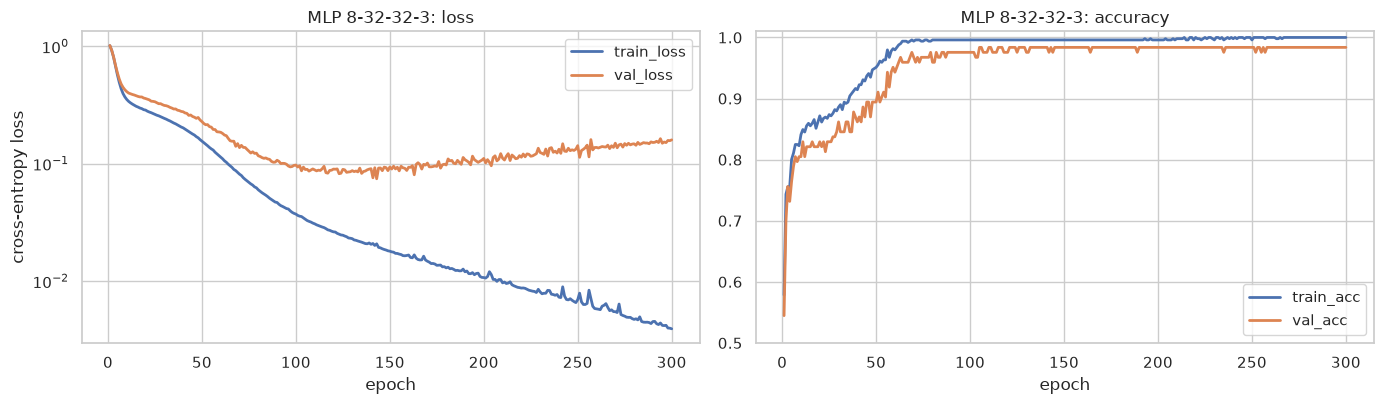

,train_loss,val_loss,train_acc,val_acc
epoch,,,,
1,1.015,1.017,0.578,0.545
10,0.353,0.411,0.841,0.805
50,0.156,0.229,0.951,0.894
100,0.037,0.097,0.996,0.976
300,0.004,0.160,1.000,0.984


In [29]:
def plot_history(history, title, name=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
    history[["train_loss", "val_loss"]].plot(ax=axes[0], lw=2)
    axes[0].set_title(f"{title}: loss")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].set_yscale("log")
    history[["train_acc", "val_acc"]].plot(ax=axes[1], lw=2)
    axes[1].set_title(f"{title}: accuracy")
    axes[1].set_ylim(0.5, 1.01)
    plt.tight_layout()
    if name:
        save_fig(name)
    plt.show()


plot_history(history, "MLP 8-32-32-3", "nb1_06_training_curves")
history.iloc[[0, 9, 49, 99, -1]]

How to read the curves:
- **Both losses fall quickly** during the first ~100 epochs: the network is learning the general rule, and the validation accuracy climbs to about **98%**.
- After that, the **training loss keeps falling** (down to 0.004: it is memorising the training buildings) while the **validation loss creeps back up** (from about 0.09 to 0.16). That is the start of **overfitting**, the same pattern as Day 2's validation curves.
- The validation **accuracy** barely changes, though: the network keeps choosing the right class, it just becomes **over-confident** on the few buildings it gets wrong, and cross-entropy punishes confident mistakes hard. This is why we watch the **loss**, not only the accuracy.

💡 **Tip:** in a real project we would stop around epoch 100, where the validation loss is lowest. Section 5 does exactly that with **early stopping**.

## 4.4 The test set, once

MLP test accuracy: 98.7%  (152 of 154 buildings)
Day 2 gradient boosting: 153 of 154 buildings (99.4%)
Figure saved to figures/nb1_07_confusion_matrix.png


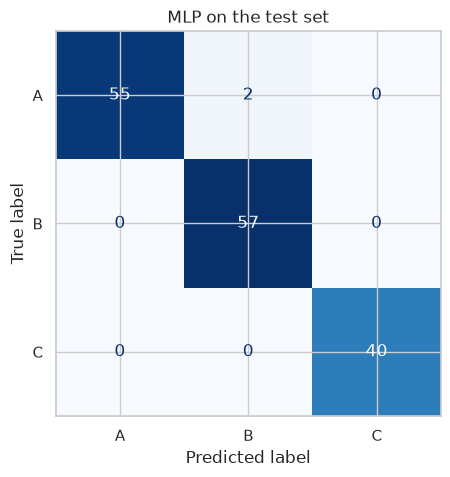

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

mlp.eval()
with torch.no_grad():
    test_pred = mlp(X_test_t.to(DEVICE)).argmax(dim=1).cpu().numpy()

test_acc = (test_pred == y_test).mean()
print(f"MLP test accuracy: {test_acc:.1%}  ({(test_pred == y_test).sum()} of {len(y_test)} buildings)")
print("Day 2 gradient boosting: 153 of 154 buildings (99.4%)")

ConfusionMatrixDisplay(confusion_matrix(y_test, test_pred), display_labels=CLASS_NAMES).plot(cmap="Blues", colorbar=False)
plt.title("MLP on the test set")
save_fig("nb1_07_confusion_matrix")
plt.show()

The network gets **152 of 154** test buildings right (98.7%). Both mistakes are class **A** buildings predicted as **B**, the neighbouring class, just across the 15 kWh/m² border. Gradient boosting on Day 2 got 153 right.

🤔 **Think about it:** after all this extra work (tensors, a training loop, a GPU), the neural network is **slightly worse** than a gradient-boosting model trained in one line on Day 2. That is the normal result on small tables with a handful of meaningful columns. Neural networks pay off when the input is **raw and high-dimensional** (pixels, words, sound), where nobody can hand-craft good features. That is exactly what notebooks 2 and 3 are about.

## 4.5 Looking inside the trained network

What did 300 epochs actually change? The architecture stays the same: only the **numbers** on the lines move. Let's compare the copy of the random starting weights we kept (`mlp_untrained`) with the trained network, drawn with the **same** line scale:

Figure saved to figures/nb1_07b_network_before_after.png


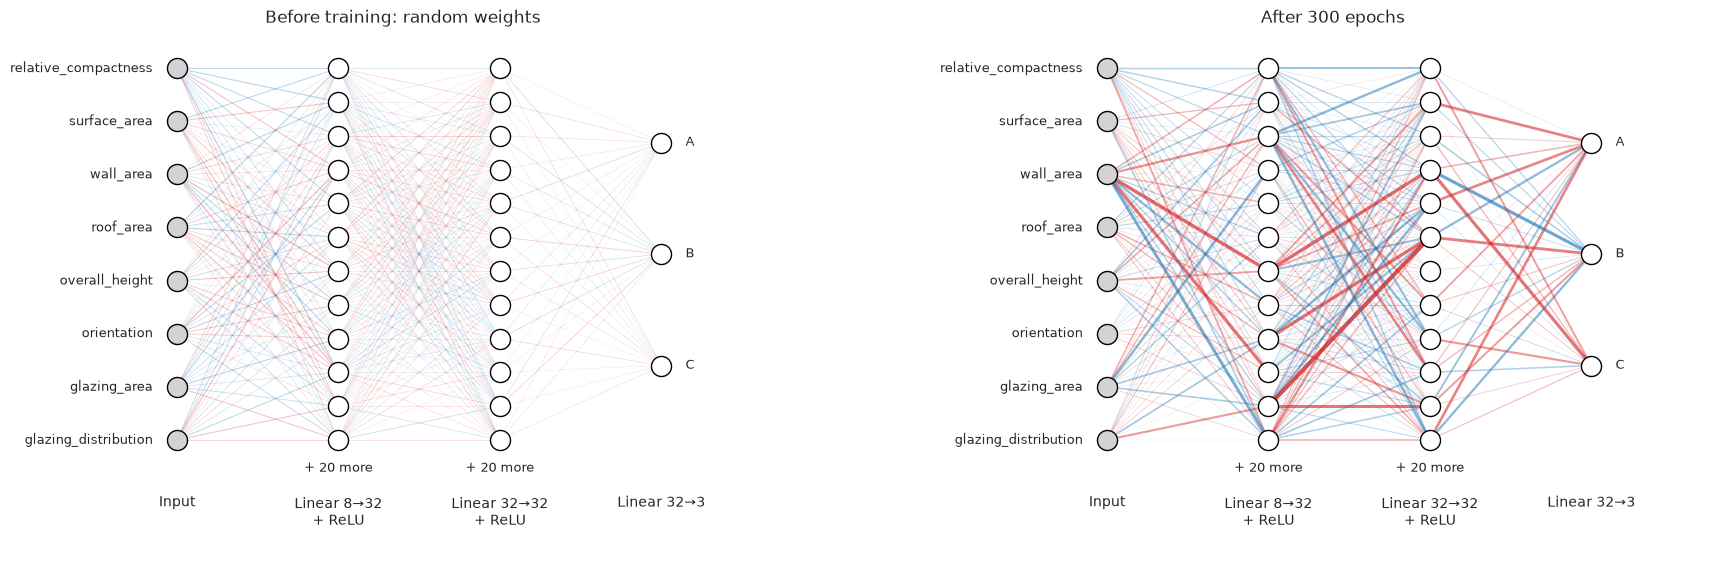

Figure saved to figures/nb1_07c_weight_histograms.png


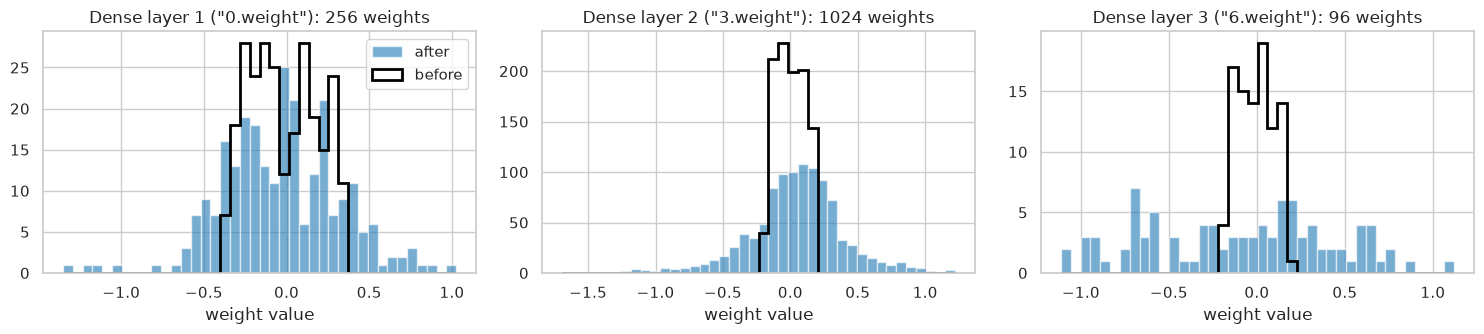

before               after             
             std    min    max   std    min   max
parameter                                        
0.weight   0.204 -0.352  0.353 0.356 -1.353 1.026
0.bias     0.221 -0.352  0.334 0.372 -0.640 0.838
3.weight   0.103 -0.176  0.176 0.361 -1.694 1.223
3.bias     0.101 -0.168  0.171 0.146 -0.169 0.353
6.weight   0.099 -0.175  0.173 0.519 -1.114 1.122
6.bias     0.039 -0.101 -0.007 0.094 -0.129 0.076

In [31]:
same_scale = max(layer.weight.abs().max().item() for layer in mlp if isinstance(layer, nn.Linear))

fig, axes = plt.subplots(1, 2, figsize=(22, 7))
draw_network(mlp_untrained, feature_cols, CLASS_NAMES, weight_scale=same_scale, ax=axes[0],
             title="Before training: random weights")
draw_network(mlp, feature_cols, CLASS_NAMES, weight_scale=same_scale, ax=axes[1],
             title="After 300 epochs")
save_fig("nb1_07b_network_before_after")
plt.show()

# The same comparison in numbers: the spread of the weights in each dense layer
linear_names = [name for name, layer in mlp.named_children() if isinstance(layer, nn.Linear)]
fig, axes = plt.subplots(1, len(linear_names), figsize=(15, 3.5))
for number, (ax, name) in enumerate(zip(axes, linear_names), start=1):
    before = getattr(mlp_untrained, name).weight.detach().cpu().numpy().ravel()
    after = getattr(mlp, name).weight.detach().cpu().numpy().ravel()
    bins = np.linspace(after.min(), after.max(), 41)               # the same bins for both
    ax.hist(after, bins=bins, color="tab:blue", alpha=0.6, label="after")
    ax.hist(before, bins=bins, histtype="step", color="black", lw=2, label="before")
    ax.set_title(f"Dense layer {number} (\"{name}.weight\"): {getattr(mlp, name).weight.numel()} weights")
    ax.set_xlabel("weight value")
axes[0].legend()
plt.tight_layout()
save_fig("nb1_07c_weight_histograms")
plt.show()

pd.concat({"before": parameter_table(mlp_untrained)[["std", "min", "max"]],
           "after": parameter_table(mlp)[["std", "min", "max"]]}, axis=1)

- **Before training** every line is thin and the weights sit in a narrow, flat box: PyTorch draws them at random between $\pm 1/\sqrt{\text{inputs}}$, about ±0.35 for the first layer (8 inputs) and ±0.18 for the others (32 inputs). The network starts as a balanced tangle that prefers no feature and no class.
- **After training** a few thick lines stand out: some connections now matter a lot more than the rest. The spread of the weights (std) has grown from 0.10–0.20 to 0.36–0.52, and the largest weight from 0.35 to almost 1.7. Most weights stay small, a few become large: that is what "learning" looks like inside.

⚠️ **Watch out:** a thick line is **not** the same as an important feature. Each feature passes through 32 + 32 neurons and is mixed with all the others, and positive and negative paths can cancel out. To ask which design parameter matters, use **permutation importance** from Day 2, which works on any model.

### Following one building through the network

Finally, let's watch one test building travel through the layers with `layer_outputs`: its 8 scaled features go in, each hidden layer turns them into 32 new numbers, and the last layer gives 3 scores, which softmax turns into probabilities.

0: Linear  : shape (1, 32)
1: ReLU    : shape (1, 32)
2: Dropout : shape (1, 32)
3: Linear  : shape (1, 32)
4: ReLU    : shape (1, 32)
5: Dropout : shape (1, 32)
6: Linear  : shape (1, 3)
Figure saved to figures/nb1_07d_one_building_through_the_network.png


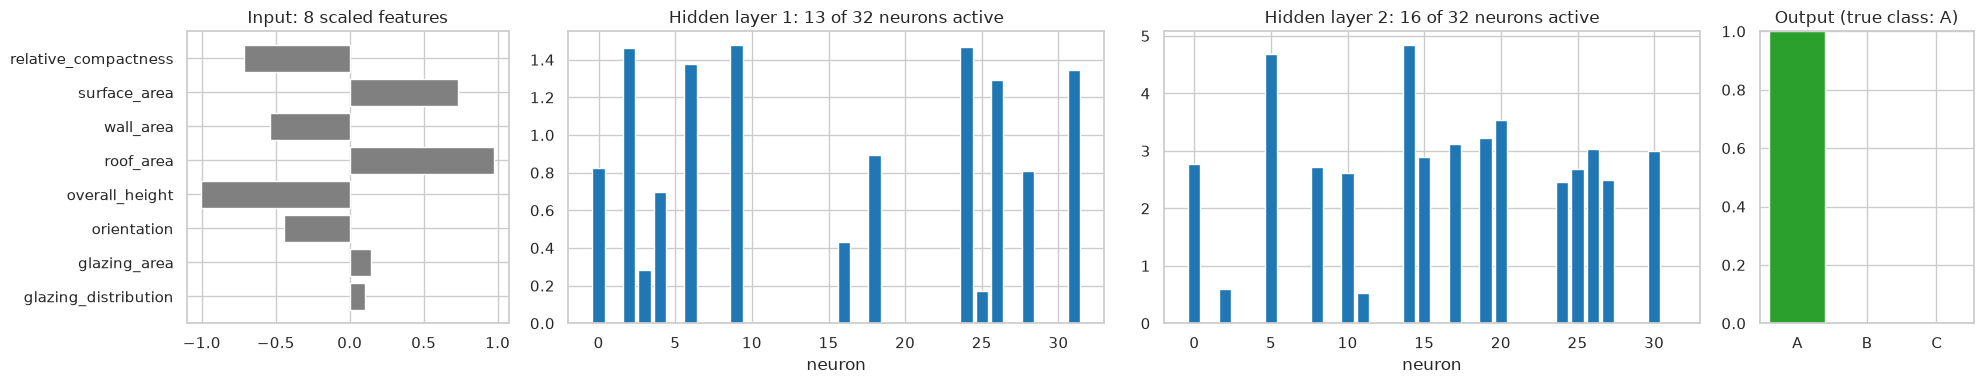

In [32]:
mlp.eval()
example = 0
steps = layer_outputs(mlp, X_test_t[example:example + 1].to(DEVICE))
for name, output in steps:
    print(f"{name:<11}: shape {tuple(output.shape)}")

hidden_1, hidden_2, scores = steps[1][1][0], steps[4][1][0], steps[6][1][0]   # after ReLU, ReLU, last Linear
probabilities = torch.softmax(scores, dim=0)

fig, axes = plt.subplots(1, 4, figsize=(20, 4), gridspec_kw={"width_ratios": [1.2, 2, 2, 0.8]})
axes[0].barh(feature_cols, X_test_t[example].numpy(), color="grey")
axes[0].invert_yaxis()
axes[0].set_title("Input: 8 scaled features")
for ax, values, name in [(axes[1], hidden_1, "Hidden layer 1"), (axes[2], hidden_2, "Hidden layer 2")]:
    ax.bar(range(len(values)), values.numpy(), color="tab:blue")
    ax.set_title(f"{name}: {(values > 0).sum()} of {len(values)} neurons active")
    ax.set_xlabel("neuron")
axes[3].bar(CLASS_NAMES, probabilities.numpy(), color="tab:green")
axes[3].set_ylim(0, 1)
axes[3].set_title(f"Output (true class: {CLASS_NAMES[y_test[example]]})")
plt.tight_layout()
save_fig("nb1_07d_one_building_through_the_network")
plt.show()

- The building enters as **8 scaled numbers** (0 = average of the training set; this one is a **low** building with a large roof and surface area).
- **Hidden layer 1** turns them into 32 new numbers, but ReLU sets most of them to 0: only **13 of 32** neurons are on for this building. Every building switches on its **own combination** of neurons; that pattern is the network's internal description of the building.
- **Hidden layer 2** combines those into 32 more abstract numbers (16 on).
- The **output** layer turns them into three scores, and softmax into probabilities: almost **100% class A**, which is correct.

Nobody told the network what the hidden neurons should mean; training chose them. That is the difference with Day 2, where **we** chose the features.

# 5. Overfitting and regularisation

Networks have **many parameters**, so they can easily **memorise** a small training set instead of learning the general rule: Day 2's overfitting, in a stronger form. To see it, we make it hard on purpose: a **big** network (3 layers of 256 neurons, about 135,000 parameters) trained on only **60** buildings.

Parameters: 134659
Figure saved to figures/nb1_08_overfitting.png


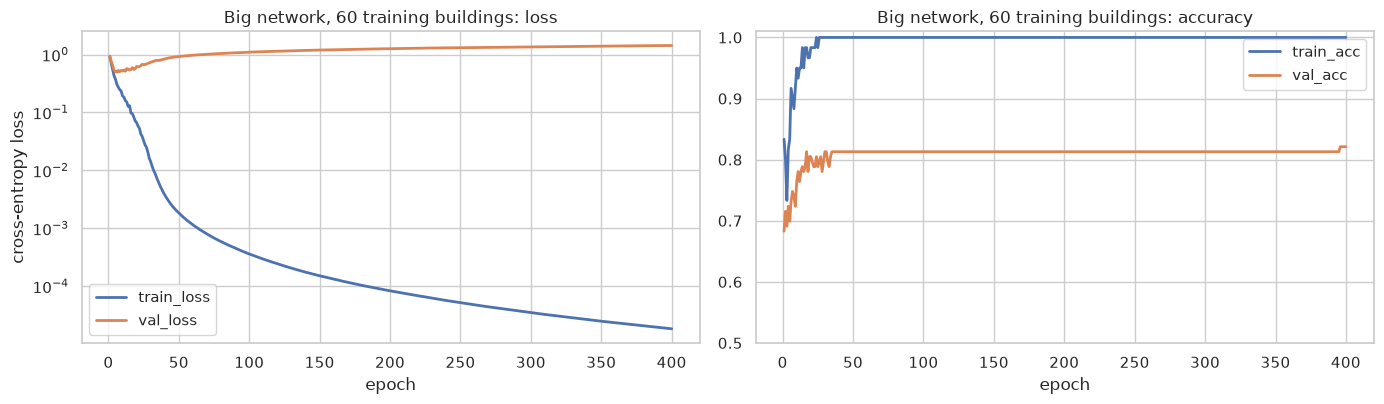

In [33]:
small_rows = np.random.default_rng(RANDOM_STATE).choice(len(X_train_t), size=60, replace=False)
X_small, y_small = X_train_t[small_rows], y_train_t[small_rows]


def loader_for(X_part, y_part):
    return DataLoader(TensorDataset(X_part, y_part), batch_size=16, shuffle=True,
                      generator=torch.Generator().manual_seed(RANDOM_STATE))


def make_big(dropout=0.0):
    return nn.Sequential(
        nn.Linear(len(feature_cols), 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, 256), nn.ReLU(), nn.Dropout(dropout),
        nn.Linear(256, len(CLASS_NAMES)),
    )


torch.manual_seed(RANDOM_STATE)
big = make_big()
print("Parameters:", sum(p.numel() for p in big.parameters()))
history_big = train(big, loader_for(X_small, y_small), epochs=400, fit_data=(X_small, y_small))
plot_history(history_big, "Big network, 60 training buildings", "nb1_08_overfitting")

A textbook case of **overfitting**:
- The **training loss** drops towards zero (about 0.00002 by the end) and the training accuracy reaches **100%** after about 30 epochs: with 135,000 parameters and only 60 buildings, the network has simply **memorised** them.
- The **validation loss** reaches its lowest point (about 0.50) in the first epochs and then **climbs to 1.43**: the network becomes more and more confident, and more and more wrong, on buildings it has not seen.
- The **validation accuracy** stays stuck at about **82%**.

### Three standard remedies

| Remedy | Idea | In PyTorch |
|---|---|---|
| **Early stopping** | Watch the validation loss, stop when it stops improving, and keep the best weights | Our `train(..., patience=30)` |
| **Dropout** | During training, randomly switch off a share of the neurons at every step, so the network cannot rely on a few memorised paths | `nn.Dropout(0.5)` between layers |
| **Weight decay** | Penalise large weights, like Day 2's Ridge regression | `Adam(..., weight_decay=1e-2)` |

And the best remedy of all: **more data**. Let's compare all four on the **validation set** (the test set stays locked, as on Day 2):

Figure saved to figures/nb1_09_regularised.png


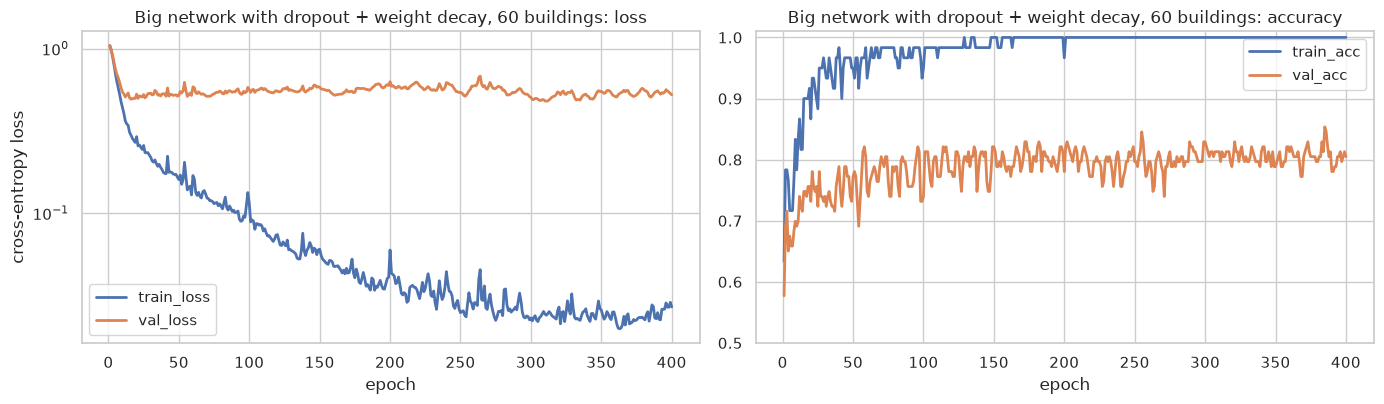

,epochs,validation loss,validation accuracy
no regularisation (60 buildings),400,1.432,0.821
early stopping,36,0.495,0.732
dropout + weight decay,400,0.524,0.805
"dropout + weight decay, ALL 491 buildings",102,0.105,0.976


In [34]:
variants = {}

torch.manual_seed(RANDOM_STATE)
model = make_big()
variants["early stopping"] = (model, train(model, loader_for(X_small, y_small), epochs=400, patience=30,
                                           fit_data=(X_small, y_small)))

torch.manual_seed(RANDOM_STATE)
model = make_big(dropout=0.5)
variants["dropout + weight decay"] = (model, train(model, loader_for(X_small, y_small), epochs=400, weight_decay=1e-2,
                                                   fit_data=(X_small, y_small)))

torch.manual_seed(RANDOM_STATE)
model = make_big(dropout=0.5)
variants["dropout + weight decay, ALL 491 buildings"] = (model, train(model, loader_for(X_train_t, y_train_t), epochs=400,
                                                                      weight_decay=1e-2, patience=30))

def validation_loss(model):
    # Loss of the model as it is now (for early stopping: the restored best weights)
    model.eval()
    with torch.no_grad():
        return nn.CrossEntropyLoss()(model(X_val_t.to(DEVICE)), y_val_t.to(DEVICE)).item()


rows = {"no regularisation (60 buildings)": {"epochs": len(history_big), "validation loss": validation_loss(big),
                                             "validation accuracy": accuracy(big, X_val_t, y_val_t)}}
for name, (model, hist) in variants.items():
    rows[name] = {"epochs": len(hist), "validation loss": validation_loss(model),
                  "validation accuracy": accuracy(model, X_val_t, y_val_t)}
comparison = pd.DataFrame(rows).T
comparison["epochs"] = comparison["epochs"].astype(int)

plot_history(variants["dropout + weight decay"][1], "Big network with dropout + weight decay, 60 buildings",
             "nb1_09_regularised")
comparison

Reading the table:
- **Early stopping** stops after 36 epochs and goes back to the weights with the lowest validation loss (0.50 instead of 1.43). **Dropout + weight decay** keep the validation loss flat around 0.52 for all 400 epochs, even though the training loss still falls (see the figure): the network can no longer memorise freely.
- Both remedies stop the network from becoming **confidently wrong**, but neither makes it **more accurate**: with only 60 examples, validation accuracy stays between **73% and 82%**. Regularisation cannot invent information that is not in the data.
- The **same big network with all 491 training buildings** reaches **97.6%** validation accuracy and a validation loss of 0.11.

**Lesson:** regularisation keeps a network honest; **more (and more varied) data** is what makes it better. This is why deep learning only took off when large datasets became available, and why notebook 3 starts from a model **pretrained** on many images.

### What regularisation does inside the network

The table shows the effect from the outside. From the inside, we can compare the weights of the memorising network (`big`) with the one trained with dropout + weight decay, and count how many hidden neurons ever switch on for the validation buildings:

Figure saved to figures/nb1_09b_regularised_weights.png


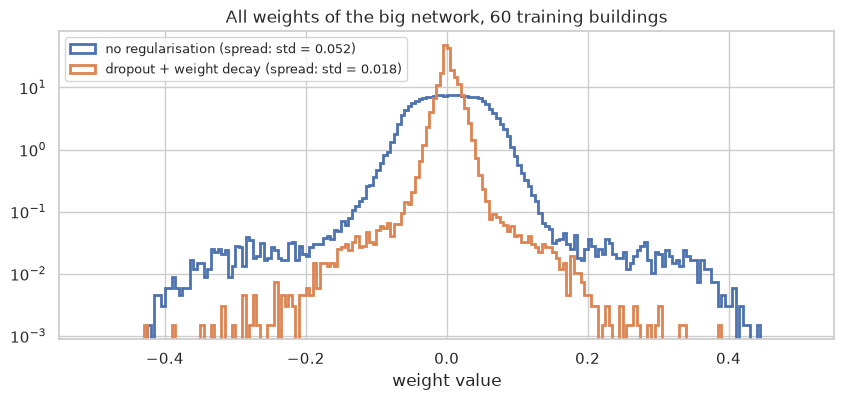

,no regularisation,dropout + weight decay
1: ReLU,255 of 256,254 of 256
4: ReLU,242 of 256,237 of 256
7: ReLU,207 of 256,244 of 256


In [35]:
def all_weights(model):
    # Every weight of every dense layer, in one long list
    return torch.cat([layer.weight.detach().cpu().ravel() for layer in model if isinstance(layer, nn.Linear)]).numpy()


def active_neurons(model, X_part):
    # For each hidden layer (after ReLU): how many neurons give a non-zero output for at least one example
    model.eval()
    counts = {}
    for name, output in layer_outputs(model, X_part.to(DEVICE)):
        if name.endswith("ReLU"):
            counts[name] = f"{(output > 0).any(dim=0).sum().item()} of {output.shape[1]}"
    return counts


compared = {"no regularisation": big, "dropout + weight decay": variants["dropout + weight decay"][0]}

fig, ax = plt.subplots(figsize=(10, 4))
for name, model in compared.items():
    weights = all_weights(model)
    ax.hist(weights, bins=200, range=(-0.5, 0.5), histtype="step", lw=2, density=True,
            label=f"{name} (spread: std = {weights.std():.3f})")
ax.set_yscale("log")
ax.set_xlabel("weight value")
ax.set_title("All weights of the big network, 60 training buildings")
ax.legend(loc="upper left", fontsize=9)
save_fig("nb1_09b_regularised_weights")
plt.show()

pd.DataFrame({name: active_neurons(model, X_val_t) for name, model in compared.items()})

- **Weight decay** works exactly as advertised: the regularised network's weights are packed around 0 (std **0.018** against **0.052**, about 3× smaller; note the log scale). Small weights mean smooth outputs that cannot jump to extreme, over-confident scores for one memorised building.
- **Dropout** shows in the last table. Without regularisation, **49** of the 256 neurons in the last hidden layer never switch on for any validation building: the memorising network relies on a few paths. With dropout, a neuron cannot count on its neighbours being there, so the work is spread out and **244 of 256** neurons stay in use.

Both are signs of a network that learned a smoother, more general rule, even though (as the table above showed) 60 buildings are still not enough to make it more accurate.

# 6. Saving and reusing a PyTorch model

A PyTorch model is saved as its **`state_dict`**: a dictionary with every weight and bias. To reuse it you need the **same architecture** (the code that builds the model) and, just as important, the **same preprocessing**. Unlike a scikit-learn `Pipeline`, a PyTorch model does not include the scaler: save it too.

In [36]:
import joblib

torch.save(mlp.state_dict(), MODEL_DIR / "energy_mlp.pt")
joblib.dump(scaler, MODEL_DIR / "energy_mlp_scaler.joblib")

# Reload, as a user would: rebuild the architecture, load the weights and the scaler
reloaded = make_mlp()
reloaded.load_state_dict(torch.load(MODEL_DIR / "energy_mlp.pt", map_location="cpu"))
reloaded.eval()
reloaded_scaler = joblib.load(MODEL_DIR / "energy_mlp_scaler.joblib")

# A new design option: compact two-storey building, 25% glazing, facing south
new_building = pd.DataFrame([{"relative_compactness": 0.86, "surface_area": 588.0, "wall_area": 294.0,
                              "roof_area": 147.0, "overall_height": 7.0, "orientation": 4,
                              "glazing_area": 0.25, "glazing_distribution": 1}])
x_new = torch.tensor(reloaded_scaler.transform(new_building[feature_cols].to_numpy()), dtype=torch.float32)
with torch.no_grad():
    probabilities = torch.softmax(reloaded(x_new), dim=1)[0]
for name, p in zip(CLASS_NAMES, probabilities):
    print(f"class {name}: {p:.1%}")

class A: 0.0%
class B: 88.7%
class C: 11.3%


💡 **Tip:** the softmax turns the three raw scores into **probabilities** that sum to 100%. A confident 98% is very different from a hesitant 40 / 35 / 25, so report both the class and the probability.

# 7. Summary

### scikit-learn or PyTorch?

| | **scikit-learn** (Days 1–3) | **PyTorch** (today) |
|---|---|---|
| Best for | Tables, small to medium data, classic models | Images, text, sound, very large data, custom architectures |
| Training loop | Hidden: `.fit()` | You write it (or a library like Ultralytics writes it for you) |
| Preprocessing | Inside a `Pipeline` | Separate: save the scaler / transforms yourself |
| Hardware | CPU | CPU, but a **GPU** makes it 10–100× faster |
| Interpretability | Coefficients, trees, permutation importance | Harder: millions of weights |

### Checklist for training a network
- [ ] Data split **before** anything else; a validation set to watch the training, a test set used **once**.
- [ ] Inputs **scaled** (tables) or normalised to 0–1 (images).
- [ ] Shapes, dtypes and devices checked when something breaks (`summary(model, input_data=...)` shows the shape after every layer).
- [ ] Loss and validation curves **plotted**: is it still learning? Is it overfitting?
- [ ] Learning rate tried at a few values (×10 apart).
- [ ] Regularisation (early stopping, dropout, weight decay) when the validation loss goes up.
- [ ] Compared with a simple **baseline** (Day 2!): a network is not automatically better.

# 8. Your turn

**Exercise 1 – Architecture.** Change the MLP of section 4: one hidden layer instead of two, 8 neurons instead of 32, or `nn.Tanh()` instead of `nn.ReLU()`. How do the training curves and the test accuracy change? What is the smallest network that still matches gradient boosting?

**Exercise 2 – Regression.** Predict the **heating load** itself (a number) instead of the class: change the last layer to 1 output, the loss to `nn.MSELoss()`, and the labels to `float32` tensors of shape `(N, 1)`. Compare the test R² with Day 2.

**Exercise 3 – Learning rates.** Train the MLP of section 4 with `lr = 1e-4`, `1e-3`, `1e-2` and `1e-1`. Plot the four validation-loss curves on one figure and explain what you see with section 3.2.

**Exercise 4 – Look inside.** On the two moons of section 2.2, train an MLP with **one** hidden layer of only **4** neurons, and another with `nn.Tanh()` instead of `nn.ReLU()`. For each, use `summary`, `draw_network` and the neuron maps of section 2.2. How many straight borders can 4 neurons draw? How does Tanh change what a neuron responds to?

In [37]:
# Your code here

# 9. Conclusions and next steps

### Key findings
- **Tensors** are NumPy arrays that can live on a GPU and compute their own gradients. On this computer, one large matrix multiplication ran about **12× faster** on the GPU than on the CPU.
- **Autograd** gives the exact slope (8.0 for $x^2 + 2x$ at $x = 3$) and **gradient descent** uses it to learn: our two-parameter line went from a loss of 34.5 to 0.13 and recovered the hidden rule (1.80 × area + 0.75, true: 1.80 × area + 0.70).
- The **learning rate** decides everything: too small (0.001) still had a loss of about 4 after 60 steps, a good one (0.02) converged in about 10 steps, a too-large one (0.12) exploded.
- **Hidden layers** bend decision borders: on the two moons, accuracy went from 88% (one neuron) to 97% (two small hidden layers).
- On the **energy classes**, a small MLP reached **98.7%** test accuracy (152/154), just below Day 2's gradient boosting (99.4%). On small tables, networks are not better than trees.
- A big network on **60** buildings **memorised** them (validation loss 0.50 → 1.43). Early stopping and dropout kept it honest; **more data** (all 491 buildings) lifted validation accuracy from about 80% to **97.6%**.

### Limitations
- The energy dataset is small, simulated and tabular: the worst possible showcase for deep learning, chosen on purpose to connect with Day 2.
- Results of networks depend on random initialisation and on many settings (architecture, learning rate, batch size, epochs). Fix the seed, and report the settings.

### Next: notebook 2
An image is just a tensor of shape `(height, width, 3)` with values from 0 to 255. In **notebook 2** we process such tensors with **OpenCV**, using hand-written rules: filters, thresholds, colours, contours. In **notebook 3** a network learns those rules by itself.

### References
- PyTorch tutorials: [Learn the Basics](https://pytorch.org/tutorials/beginner/basics/intro.html)
- 3Blue1Brown, [Neural networks](https://www.3blue1brown.com/topics/neural-networks) (video series): the best visual explanation of neurons, gradient descent and backpropagation
- Géron, A. (2022), *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), chapters 10–11
- Tsanas, A. & Xifara, A. (2012), *Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools*, Energy and Buildings 49